# 50-Cell Cable Model — CiPA/Gong Human Ventricular Cardiomyocyte

**Converted from MATLAB ring model to Python linear cable model**

This notebook implements a 1D cable (linear chain) of 50 coupled human ventricular
cardiomyocytes based on the O'Hara–Rudy CiPA model with Gong/Heijman beta-adrenergic
signaling. The original MATLAB code used a 500-node closed ring; here we use:

- **50 cells** in a **linear cable** (no-flux / sealed-end boundary conditions)
- Same ionic model (67 state variables per cell)
- Same beta-adrenergic signaling (57 biochemical states, spatially uniform)
- Same drug models (quinidine hERG Markov + Hill block; ISO signaling)

## Four Test Conditions
| Case | ISO (µM) | Quinidine (nM) | Description |
|------|----------|----------------|-------------|
| 1    | 0        | 0              | No drugs (Control) |
| 2    | 0        | 3237           | Quinidine alone |
| 3    | 1        | 0              | ISO alone |
| 4    | 1        | 3237           | ISO + Quinidine |

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.sparse import diags, eye as speye, kron as skron, csc_matrix
import matplotlib.pyplot as plt
import time
import warnings

plt.rcParams.update({'font.size': 12, 'figure.figsize': (14, 8)})

## 1. Physical and Model Constants

In [2]:
# Fundamental constants
R = 8314.0       # Gas constant (J/(kmol·K))
T = 310.0        # Temperature (K)
F = 96485.0      # Faraday's constant (C/mol)

# Cell geometry
L_cell = 0.01    # Cell length (cm)
rad = 0.0011     # Cell radius (cm)
vcell = 1000.0 * 3.14 * rad * rad * L_cell
Ageo = 2.0 * 3.14 * rad * rad + 2.0 * 3.14 * rad * L_cell
Acap = 2.0 * Ageo
vmyo = 0.68 * vcell
vnsr = 0.0552 * vcell
vjsr = 0.0048 * vcell
vss = 0.02 * vcell

# Cable parameters
NUM_CELLS = 50
DX = 0.02         # Spatial discretization (cm)
DIFFUSION = 0.0011 / (2.0 * 0.126)  # Diffusion coefficient (cm^2/ms)
NUM_STATES = 67    # States per cell

print(f"Cable: {NUM_CELLS} cells, dx={DX} cm, total length={NUM_CELLS*DX} cm")
print(f"Diffusion coefficient: {DIFFUSION:.6f} cm^2/ms")
print(f"States per cell: {NUM_STATES}, total states: {NUM_CELLS*NUM_STATES}")

Cable: 50 cells, dx=0.02 cm, total length=1.0 cm
Diffusion coefficient: 0.004365 cm^2/ms
States per cell: 67, total states: 3350


## 2. Beta-Adrenergic Signaling Constants

In [3]:
def constants_signaling(iso_conc):
    """Heijman 2011 signaling constants. Translated from Constants_SignalingMyokit.m"""
    c = {}
    c['iso_L'] = iso_conc
    c['ibmx'] = 0.0
    c['phys_T'] = 310.0
    c['F'] = 96487.0
    c['phys_R'] = 8314.0

    # Cell geometry
    c['length'] = 0.01
    c['cell_pi'] = 3.14159265358979312
    c['radius'] = 0.0011
    c['geoArea'] = 2.0 * c['cell_pi'] * c['radius'] * (c['radius'] + c['length'])
    c['volume'] = 1000.0 * c['cell_pi'] * c['radius'] * c['radius'] * c['length']
    c['v_cav'] = 0.02 * c['volume']
    c['v_eca'] = 0.04 * c['volume']
    c['v_cyt'] = c['volume'] * 0.678
    c['vr_cav'] = c['volume'] / c['v_cav']
    c['vr_eca'] = c['volume'] / c['v_eca']
    c['vr_cyt'] = c['volume'] / c['v_cyt']

    # cAMP diffusion
    c['j_cav_eca'] = 5e-15 * 1e6
    c['j_cav_cyt'] = 7.5e-14 * 1e6
    c['j_eca_cyt'] = 9e-15 * 1e6

    # PKA
    c['PKA_tot'] = 0.5
    c['f_cav'] = 0.0388
    c['f_eca'] = 0.1
    c['f_cyt'] = 1.0 - c['f_cav'] - c['f_eca']
    c['PKA_eca'] = c['f_eca'] * c['PKA_tot'] * c['vr_eca']
    c['PKA_cav'] = c['f_cav'] * c['PKA_tot'] * c['vr_cav']
    c['PKA_cyt'] = c['f_cyt'] * c['PKA_tot'] * c['vr_cyt']
    c['PKI_tot'] = 0.2 * c['PKA_tot']
    c['f_pki_cav'] = c['f_cav']
    c['f_pki_eca'] = c['f_eca']
    c['f_pki_cyt'] = 1.0 - c['f_pki_cav'] - c['f_pki_eca']
    c['PKI_cav'] = c['f_pki_cav'] * c['PKI_tot'] * c['vr_cav']
    c['PKI_eca'] = c['f_pki_eca'] * c['PKI_tot'] * c['vr_eca']
    c['PKI_cyt'] = c['f_pki_cyt'] * c['PKI_tot'] * c['vr_cyt']
    c['f_pki'] = 50.0
    c['K_pki'] = 0.01 / 50.0
    c['b_pki'] = c['f_pki'] * c['K_pki']

    # PKA activation rates - cav
    c['pka_cav_f1'] = 100.0; c['pka_cav_f2'] = 100.0; c['pka_cav_f3'] = 100.0
    c['pka_cav_K1'] = 2.4984; c['pka_cav_K2'] = 11.359; c['pka_cav_K3'] = 0.3755
    c['pka_cav_b1'] = c['pka_cav_f1'] * c['pka_cav_K1']
    c['pka_cav_b2'] = c['pka_cav_f2'] * c['pka_cav_K2']
    c['pka_cav_b3'] = c['pka_cav_f3'] * c['pka_cav_K3']

    # PKA activation rates - eca (same as cav)
    c['pka_eca_f1'] = c['pka_cav_f1']; c['pka_eca_f2'] = c['pka_cav_f2']; c['pka_eca_f3'] = c['pka_cav_f3']
    c['pka_eca_K1'] = c['pka_cav_K1']; c['pka_eca_K2'] = c['pka_cav_K2']; c['pka_eca_K3'] = c['pka_cav_K3']
    c['pka_eca_b1'] = c['pka_eca_f1'] * c['pka_eca_K1']
    c['pka_eca_b2'] = c['pka_eca_f2'] * c['pka_eca_K2']
    c['pka_eca_b3'] = c['pka_eca_f3'] * c['pka_eca_K3']

    # PKA activation rates - cyt
    c['pka_cyt_f1'] = c['pka_cav_f1']; c['pka_cyt_f2'] = c['pka_cav_f2']; c['pka_cyt_f3'] = c['pka_cav_f3']
    c['pka_cyt_K1'] = 0.1088; c['pka_cyt_K2'] = 0.4612; c['pka_cyt_K3'] = 0.3755
    c['pka_cyt_b1'] = c['pka_cyt_f1'] * c['pka_cyt_K1']
    c['pka_cyt_b2'] = c['pka_cyt_f2'] * c['pka_cyt_K2']
    c['pka_cyt_b3'] = c['pka_cyt_f3'] * c['pka_cyt_K3']

    # PP1
    c['f'] = 0.3; c['kp'] = 0.010145; c['kdp'] = 0.0035731
    c['Kp'] = 0.001469; c['Kdp'] = 1.95259999999999991e-05
    c['PP1_eca'] = 0.1; c['PP1_cav'] = 0.25; c['PP1_cyt'] = 0.2
    c['pp1_K'] = 0.001
    c['inhib1_tot'] = c['f'] / (1.0 - c['f']) * c['pp1_K'] + c['f'] * c['PP1_cyt']
    c['PP2A'] = 1.0

    # PDE
    c['PDE2_tot'] = 0.029268
    c['f_pde2_cav'] = 0.16957; c['f_pde2_eca'] = 2.12570000000000006e-04
    c['f_pde2_cyt'] = 1.0 - c['f_pde2_cav'] - c['f_pde2_eca']
    c['f_pde2_part'] = c['f_pde2_cav'] + c['f_pde2_eca']
    c['f_pde_part'] = 0.2; c['f_pde4_part'] = 0.125
    c['f_pde4_cav'] = 0.12481
    c['f_pde4_eca'] = c['f_pde4_part'] - c['f_pde4_cav']
    c['f_pde4_cyt'] = 1.0 - c['f_pde4_part']
    c['kPDE2'] = 20.0; c['kPDE3'] = 2.5; c['kPDE4'] = 4.0
    c['KmPDE2'] = 50.0; c['KmPDE3'] = 0.8; c['KmPDE4'] = 1.4
    c['KmIbmxPde2'] = 21.58; c['h_ibmx_pde2'] = 1.167
    c['h_ibmx_pde3'] = 0.7629; c['h_ibmx_pde4'] = 0.9024
    c['KmIbmxPde3'] = 2.642; c['KmIbmxPde4'] = 11.89
    c['KPDEp'] = 0.52218; c['delta_k_pde34'] = 3.0
    c['ff_pde3_cyt'] = 0.35; c['kfPDEp'] = 0.0196
    c['r_pde34_frac'] = 3.71
    c['r_pde3_cyt'] = c['ff_pde3_cyt'] / (1.0 - c['ff_pde3_cyt'])
    c['kbPDEp'] = c['KPDEp'] * c['kfPDEp']

    alpha = (c['r_pde3_cyt'] * (c['f_pde4_part'] * (1.0 + c['r_pde34_frac'] - c['r_pde34_frac'] * c['f_pde2_part'] - c['f_pde_part']) + c['f_pde2_part'] * (c['f_pde_part'] - 1.0)) + c['r_pde34_frac'] * c['f_pde4_part'] * (c['f_pde_part'] - c['f_pde2_part']))
    beta = (c['f_pde4_part'] * (1.0 + c['r_pde34_frac'] + c['f_pde_part'] * (c['r_pde3_cyt'] - c['r_pde34_frac'])) - c['f_pde_part'] * (1.0 + c['r_pde3_cyt']))
    c['pde_PDE3_tot_alpha'] = alpha
    c['pde_PDE3_tot_beta'] = beta
    c['PDE3_tot'] = alpha / beta * c['PDE2_tot']
    c['PDE4_tot'] = ((c['f_pde_part'] - c['f_pde2_part']) * c['PDE2_tot'] + c['f_pde_part'] * c['PDE3_tot']) / ((1.0 + c['r_pde34_frac']) * c['f_pde4_part'] - c['f_pde_part'])

    ibmx = c['ibmx']
    c['ibmx_h2'] = ibmx ** c['h_ibmx_pde2'] if ibmx > 0 else 0.0
    c['ibmx_h3'] = ibmx ** c['h_ibmx_pde3'] if ibmx > 0 else 0.0
    c['ibmx_h4'] = ibmx ** c['h_ibmx_pde4'] if ibmx > 0 else 0.0
    c['ibmx2'] = (1.0 - c['ibmx_h2'] / (c['KmIbmxPde2'] + c['ibmx_h2'])) * c['PDE2_tot'] if (c['KmIbmxPde2'] + c['ibmx_h2']) != 0 else c['PDE2_tot']
    c['ibmx3'] = (1.0 - c['ibmx_h3'] / (c['KmIbmxPde3'] + c['ibmx_h3'])) * c['PDE3_tot'] if (c['KmIbmxPde3'] + c['ibmx_h3']) != 0 else c['PDE3_tot']
    c['ibmx4'] = (1.0 - c['ibmx_h4'] / (c['KmIbmxPde4'] + c['ibmx_h4'])) * c['PDE4_tot'] if (c['KmIbmxPde4'] + c['ibmx_h4']) != 0 else c['PDE4_tot']

    # When ibmx=0, the fraction terms simplify:
    c['ibmx2'] = c['PDE2_tot']
    c['ibmx3'] = c['PDE3_tot']
    c['ibmx4'] = c['PDE4_tot']

    c['f_pde3_cav'] = c['r_pde34_frac'] * c['f_pde4_part'] * c['PDE4_tot'] / c['PDE3_tot']
    c['f_pde3_cyt'] = 1.0 - c['f_pde3_cav']
    c['PDE2_cav'] = c['ibmx2'] * c['f_pde2_cav'] * c['vr_cav']
    c['PDE2_eca'] = c['ibmx2'] * c['f_pde2_eca'] * c['vr_eca']
    c['PDE2_cyt'] = c['ibmx2'] * c['f_pde2_cyt'] * c['vr_cyt']
    c['PDE3_cav'] = c['ibmx3'] * c['f_pde3_cav'] * c['vr_cav']
    c['PDE3_cyt'] = c['ibmx3'] * c['f_pde3_cyt'] * c['vr_cyt']
    c['PDE4_cav'] = c['ibmx4'] * c['f_pde4_cav'] * c['vr_cav']
    c['PDE4_eca'] = c['ibmx4'] * c['f_pde4_eca'] * c['vr_eca']
    c['PDE4_cyt'] = c['ibmx4'] * c['f_pde4_cyt'] * c['vr_cyt']

    # Receptors and G-proteins
    c['beta_R_b1_tot'] = 0.85 * 0.025
    c['beta_R_b2_tot'] = 0.15 * 0.025
    c['Gs_tot'] = 224.0 * c['beta_R_b1_tot']
    c['Gi_tot'] = 0.5
    c['f_Gs_eca'] = 0.5664; c['f_Gs_cav'] = 0.0011071
    c['f_Gs_cyt'] = 1.0 - c['f_Gs_cav'] - c['f_Gs_eca']
    c['f_Gi_cav'] = 0.85; c['f_Gi_eca'] = 1.0 - c['f_Gi_cav']
    c['f_Rb1_cav'] = 0.081161; c['f_Rb1_eca'] = 0.48744
    c['f_Rb1_cyt'] = 1.0 - c['f_Rb1_cav'] - c['f_Rb1_eca']
    c['f_Rb2_cav'] = 0.85; c['f_Rb2_eca'] = 1.0 - c['f_Rb2_cav']
    c['k_b1_l'] = 0.567; c['k_b1_c'] = 2.449; c['k_b1_h'] = 0.062
    c['k_b2_n'] = 1.053; c['k_b2_h'] = 0.012; c['k_b2_a'] = 1.6655
    c['k_b2_c'] = 1.8463; c['k_b2_l'] = 1.053; c['k_b2_f'] = 0.1
    c['k_act1_Gs'] = 4.9054; c['k_act2_Gs'] = 0.25945
    c['k_act1_Gi'] = 4.0; c['k_act2_Gi'] = 0.05
    c['k_hydr_Gs'] = 0.8; c['k_hydr_Gi'] = 0.8
    c['k_reas_Gs'] = 1210.0; c['k_reas_Gi'] = 1210.0
    c['rate_bds'] = 0.35
    c['k_grk_dp'] = c['rate_bds'] * 0.0009833
    c['k_grk_p'] = c['rate_bds'] * 0.00133
    c['k_pka_p'] = c['rate_bds'] * 0.0065
    c['k_pka_dp'] = 0.15629 * c['k_pka_p']

    IL = iso_conc
    # beta_cav derived
    c['beta_cav_GRK'] = 1.0
    c['beta_cav_R_b1_tot'] = c['f_Rb1_cav'] * c['beta_R_b1_tot'] * c['vr_cav']
    c['beta_cav_k_GsAct_b2'] = 1.0
    c['beta_cav_R_b2_tot'] = c['f_Rb2_cav'] * c['beta_R_b2_tot'] * c['vr_cav']
    c['beta_cav_Rb2_pka_f_a'] = (c['k_b2_f'] + IL) * (c['k_b2_n'] + IL) / c['k_b2_n']
    c['beta_cav_Gs_f_c22'] = c['k_b2_c'] * c['k_b2_h'] * c['k_b1_l'] * (c['k_b1_h'] + IL) * (c['k_b2_l'] + IL)
    c['beta_cav_Gs_f_a'] = c['k_b1_l'] * c['k_b2_l'] * (c['k_b1_h'] + IL) * (c['k_b2_h'] + IL)
    c['beta_cav_Gs_f_c33'] = c['k_b1_c'] * c['k_b2_c'] * c['k_b1_h'] * c['k_b2_h'] * (c['k_b1_l'] + IL) * (c['k_b2_l'] + IL)
    c['beta_cav_Gs_f_c11'] = c['k_b1_c'] * c['k_b1_h'] * c['k_b2_l'] * (c['k_b2_h'] + IL) * (c['k_b1_l'] + IL)

    # beta_eca derived
    c['beta_eca_GRK'] = 1.0
    c['beta_eca_k_GsAct_b2'] = 1.0
    c['beta_eca_R_b2_tot'] = c['f_Rb2_eca'] * c['beta_R_b2_tot'] * c['vr_eca']
    c['beta_eca_R_b1_tot'] = c['f_Rb1_eca'] * c['beta_R_b1_tot'] * c['vr_eca']
    c['beta_eca_Rb2_pka_f_a'] = (c['k_b2_f'] + IL) * (c['k_b2_n'] + IL) / c['k_b2_n']
    c['beta_eca_Gs_f_c11'] = c['k_b1_c'] * c['k_b1_h'] * c['k_b2_l'] * (c['k_b2_h'] + IL) * (c['k_b1_l'] + IL)
    c['beta_eca_Gs_f_c33'] = c['k_b1_c'] * c['k_b2_c'] * c['k_b1_h'] * c['k_b2_h'] * (c['k_b1_l'] + IL) * (c['k_b2_l'] + IL)
    c['beta_eca_Gs_f_a'] = c['k_b1_l'] * c['k_b2_l'] * (c['k_b1_h'] + IL) * (c['k_b2_h'] + IL)
    c['beta_eca_Gs_f_c22'] = c['k_b2_c'] * c['k_b2_h'] * c['k_b1_l'] * (c['k_b1_h'] + IL) * (c['k_b2_l'] + IL)

    # beta_cyt derived
    c['beta_cyt_R_b1_tot'] = c['f_Rb1_cyt'] * c['beta_R_b1_tot'] * c['vr_cyt']
    c['beta_cyt_GRK'] = 1.0
    c['beta_cyt_Rb1_np_f_a'] = (c['k_b1_h'] + IL) * (c['k_b1_l'] + IL) / c['k_b1_l']

    # AC
    c['ATP'] = 5000.0; c['KmATP'] = 315.0
    c['AC_tot'] = 3.0 * c['beta_R_b1_tot']
    c['f_AC47_eca'] = 0.16479; c['f_AC56_cav'] = 0.087459
    c['f_AC56_AC47'] = 1.0 / (1.0 + 0.35)
    c['hGsAC47'] = 1.0043; c['hGsAC56'] = 1.3574; c['hGsGiAC56'] = 0.6623
    c['KmGsAC47'] = 0.031544; c['KmGsAC56'] = 0.0852; c['KmGiAC56'] = 0.0465
    c['KmGsGiAC56'] = 0.4824
    c['basalAC47'] = 0.03135; c['basalAC56'] = 0.037696
    c['afAC47'] = 3.3757; c['afAC56'] = 41.32
    c['vGsGiAC56'] = 0.8569
    c['AC47_cyt'] = (1.0 - c['f_AC47_eca']) * (1.0 - c['f_AC56_AC47']) * c['AC_tot'] * c['vr_cyt']
    c['AC56_cav'] = c['f_AC56_cav'] * c['f_AC56_AC47'] * c['AC_tot'] * c['vr_cav']
    c['fATP'] = c['ATP'] / (c['KmATP'] + c['ATP'])
    c['AC47_eca'] = c['f_AC47_eca'] * (1.0 - c['f_AC56_AC47']) * c['AC_tot'] * c['vr_eca']
    c['AC56_cyt'] = (1.0 - c['f_AC56_cav']) * c['f_AC56_AC47'] * c['AC_tot'] * c['vr_cyt']

    # Substrate phosphorylation rates
    c['ka_inak'] = 0.015265; c['kp_inak'] = 0.092455; c['Ka_inak'] = 0.0011001; c['Kp_inak'] = 5.7392
    c['Ka_ina'] = 0.10988; c['Kp_ina'] = 7.8605; c['ka_ina'] = 0.01368; c['kp_ina'] = 0.052811
    c['ka_plb'] = 0.11348; c['kp_plb'] = 0.48302; c['Ka_plb'] = 9.88539999999999992e-04; c['Kp_plb'] = 0.80737
    c['ka_ikur'] = 0.069537; c['kp_ikur'] = 0.317; c['Ka_ikur'] = 0.27623; c['Kp_ikur'] = 0.002331
    c['ka_iks'] = 0.16305; c['kp_iks'] = 1.0542; c['Ka_iks'] = 9.97940000000000003e-05; c['Kp_iks'] = 1.11470000000000002e-04
    c['M'] = 0.01; c['iks_sig_L'] = 0.0001; c['iks_sig_K'] = 0.01
    c['Yotiao'] = 0.025; c['IKs_tot'] = 0.025
    psum = 1.0 + (c['Yotiao'] - c['PKA_eca']) / c['M']
    c['iks_sig_PKAf'] = c['M'] / 2.0 * (np.sqrt(psum**2 + 4.0 * c['PKA_eca'] / c['M']) - psum)
    pp1sum = 1.0 + (c['Yotiao'] - c['PP1_eca']) / c['iks_sig_K']
    c['PP1f_eca'] = c['iks_sig_K'] / 2.0 * (np.sqrt(pp1sum**2 + 4.0 * c['PP1_eca'] / c['iks_sig_K']) - pp1sum)
    iksfsum = 1.0 + (c['Yotiao'] - c['IKs_tot']) / c['iks_sig_L']
    c['IKsf'] = c['iks_sig_L'] / 2.0 * (np.sqrt(iksfsum**2 + 4.0 * c['IKs_tot'] / c['iks_sig_L']) - iksfsum)
    c['Yotiaof'] = (c['Yotiao'] - c['IKs_tot'] + c['IKsf']) / ((1.0 + c['PP1f_eca'] / c['iks_sig_K']) * (1.0 + c['iks_sig_PKAf'] / c['M']))
    c['IKs_arn'] = c['IKsf'] * c['Yotiaof'] * c['iks_sig_PKAf'] / (c['iks_sig_L'] * c['M'])
    c['IKs_arp'] = c['IKs_arn'] * c['PP1f_eca'] / c['iks_sig_K']

    # Troponin
    c['ka_tni'] = 0.10408; c['kp_tni'] = 0.052633
    c['Ka_tni'] = 2.71430000000000008e-05; c['Kp_tni'] = 0.26714

    # RyR and ICaL AKAP
    c['RyR_tot'] = 0.125; c['RyR_akap'] = 0.125
    c['ka_ryr'] = 0.0025548; c['kp_ryr'] = 0.0038257
    c['Ka_ryr'] = 6.62979999999999944e-05; c['Kp_ryr'] = 0.043003
    c['Mr'] = 0.01; c['Lr'] = 0.0001; c['Kr'] = 0.01
    ryrf_sum = 1.0 + (c['RyR_akap'] - c['RyR_tot']) / c['Lr']
    c['RyRf'] = c['Lr'] / 2.0 * (np.sqrt(ryrf_sum**2 + 4.0 * c['RyR_tot'] / c['Lr']) - ryrf_sum)

    c['ICaL_tot'] = 0.025; c['ICaL_akap'] = 0.025
    c['ka_ical'] = 5.10090000000000044e-04; c['kp_ical'] = 0.0006903
    c['Ka_ical'] = 1.27019999999999993e-06; c['Kp_ical'] = 0.0063064
    c['Mi'] = 0.01; c['Li'] = 0.0001; c['Ki'] = 0.01
    icalf_sum = 1.0 + (c['ICaL_akap'] - c['ICaL_tot']) / c['Li']
    c['ICaLf'] = c['Li'] / 2.0 * (np.sqrt(icalf_sum**2 + 4.0 * c['ICaL_tot'] / c['Li']) - icalf_sum)

    # Cubic solution for PP1f_cav
    b_pp1 = c['ICaL_akap'] + c['RyR_akap'] + c['Ki'] + c['Kr'] - c['PP1_cav']
    c_pp1 = c['ICaL_akap'] * c['Kr'] + c['RyR_akap'] * c['Ki'] + c['Ki'] * c['Kr'] - c['PP1_cav'] * (c['Ki'] + c['Kr'])
    d_pp1 = c['PP1_cav'] * c['Ki'] * c['Kr']
    rr = -d_pp1 / 27.0 * b_pp1**3 - b_pp1**2 * c_pp1**2 / 108.0 + b_pp1 * c_pp1 * d_pp1 / 6.0 + c_pp1**3 / 27.0 + d_pp1**2 / 4.0
    yi = np.sqrt(-rr) if rr < 0 else 0.0
    yr = (np.sqrt(rr) if rr > 0 else 0.0) + d_pp1 / 2.0 + b_pp1 * c_pp1 / 6.0 - b_pp1**3 / 27.0
    mag = (yr**2 + yi**2) ** (1.0/6.0)
    arg = np.arctan2(yi, yr) / 3.0
    x_pp1 = (c_pp1 / 3.0 - b_pp1**2 / 9.0) / (mag**2) if mag > 0 else 0.0
    c['PP1f_cav'] = mag * np.cos(arg) * (1.0 - x_pp1) - b_pp1 / 3.0

    # Cubic solution for PKAf_cav
    b_pka = c['ICaL_akap'] + c['RyR_akap'] + c['Mi'] + c['Mr'] - c['PKA_cav']
    c_pka = c['ICaL_akap'] * c['Mr'] + c['RyR_akap'] * c['Mi'] + c['Mi'] * c['Mr'] - c['PKA_cav'] * (c['Mi'] + c['Mr'])
    d_pka = c['PKA_cav'] * c['Mi'] * c['Mr']
    rr2 = -d_pka / 27.0 * b_pka**3 - b_pka**2 * c_pka**2 / 108.0 + b_pka * c_pka * d_pka / 6.0 + c_pka**3 / 27.0 + d_pka**2 / 4.0
    yr2 = (np.sqrt(rr2) if rr2 > 0 else 0.0) + d_pka / 2.0 + b_pka * c_pka / 6.0 - b_pka**3 / 27.0
    yi2 = np.sqrt(-rr2) if rr2 < 0 else 0.0
    mag2 = (yr2**2 + yi2**2) ** (1.0/6.0)
    arg2 = np.arctan2(yi2, yr2) / 3.0
    x_pka = (c_pka / 3.0 - b_pka**2 / 9.0) / (mag2**2) if mag2 > 0 else 0.0
    c['akap_sig_PKAf'] = mag2 * np.cos(arg2) * (1.0 - x_pka) - b_pka / 3.0

    c['RyR_akapf'] = (c['RyR_akap'] - c['RyR_tot'] + c['RyRf']) / ((c['PP1f_cav'] / c['Kr'] + 1.0) * (c['akap_sig_PKAf'] / c['Mr'] + 1.0))
    c['RyR_arn'] = c['RyRf'] * c['RyR_akapf'] * c['akap_sig_PKAf'] / (c['Lr'] * c['Mr'])
    c['RyR_arp'] = c['RyR_arn'] * c['PP1f_cav'] / c['Kr']
    c['ICaL_akapf'] = (c['ICaL_akap'] - c['ICaL_tot'] + c['ICaLf']) / ((c['PP1f_cav'] / c['Ki'] + 1.0) * (c['akap_sig_PKAf'] / c['Mi'] + 1.0))
    c['ICaL_arn'] = c['ICaLf'] * c['ICaL_akapf'] * c['akap_sig_PKAf'] / (c['Li'] * c['Mi'])
    c['ICaL_arp'] = c['ICaL_arn'] * c['PP1f_cav'] / c['Ki']

    # Electrophysiology references
    c['beta_0'] = 0.6667 * 4.75
    c['irel_fhat_ratio'] = 0.0329 + c['RyR_arn'] / c['RyR_tot']
    c['ical_f_hat_ratio'] = 0.0269 + c['ICaL_arn'] / c['ICaL_tot']
    c['iks_f_hat_ratio'] = 0.0306 + c['IKs_arn'] / c['IKs_tot']

    return c

print("Signaling constants function defined.")

Signaling constants function defined.


## 3. Signaling Model (57 biochemical states)

In [4]:
def model_signaling(t, y, c):
    """Heijman 2011 signaling ODE. 57 state variables.
    Translated from Model_SignalingMyokit.m"""
    ydot = np.zeros(57)

    # Unpack states
    beta_cav_Gs_aGTP = y[0]; beta_eca_Gs_aGTP = y[1]; beta_cyt_Gs_aGTP = y[2]
    beta_cav_Gs_bg = y[3]; beta_eca_Gs_bg = y[4]; beta_cyt_Gs_bg = y[5]
    beta_cav_Gs_aGDP = y[6]; beta_eca_Gs_aGDP = y[7]; beta_cyt_Gs_aGDP = y[8]
    cAMP_cav = y[9]; cAMP_eca = y[10]; cAMP_cyt = y[11]
    beta_cav_Rb1_pka_tot = y[12]; beta_eca_Rb1_pka_tot = y[13]; beta_cyt_Rb1_pka_tot = y[14]
    beta_cav_Rb1_grk_tot = y[15]; beta_eca_Rb1_grk_tot = y[16]; beta_cyt_Rb1_grk_tot = y[17]
    pka_cav_ARC = y[18]; pka_cav_A2RC = y[19]; pka_cav_A2R = y[20]; pka_cav_C = y[21]; pka_cav_PKIC = y[22]
    pka_eca_ARC = y[23]; pka_eca_A2RC = y[24]; pka_eca_A2R = y[25]; pka_eca_C = y[26]; pka_eca_PKIC = y[27]
    pka_cyt_ARC = y[28]; pka_cyt_A2RC = y[29]; pka_cyt_A2R = y[30]; pka_cyt_C = y[31]; pka_cyt_PKIC = y[32]
    PDE3_P_cav = y[33]; PDE3_P_cyt = y[34]; PDE4_P_cav = y[35]; PDE4_P_eca = y[36]; PDE4_P_cyt = y[37]
    inhib1_p = y[38]
    ICaLp = y[39]; IKsp = y[40]; iup_f_plb = y[41]; f_tni = y[42]
    ina_f_ina = y[43]; f_inak = y[44]; RyRp = y[45]; f_ikur = y[46]
    beta_cav_Rb2_pka_tot = y[47]; beta_cav_Rb2_grk_tot = y[48]
    beta_eca_Rb2_pka_tot = y[49]; beta_eca_Rb2_grk_tot = y[50]
    beta_cav_Gi_aGTP = y[51]; beta_cav_Gi_bg = y[52]; beta_cav_Gi_aGDP = y[53]
    beta_eca_Gi_aGTP = y[54]; beta_eca_Gi_bg = y[55]; beta_eca_Gi_aGDP = y[56]

    IL = c['iso_L']

    # ---- Beta-1 receptor / Gs signaling (cav) ----
    Gs_cav_abg = c['f_Gs_cav'] * c['Gs_tot'] * c['vr_cav'] - beta_cav_Gs_aGTP - beta_cav_Gs_bg - beta_cav_Gs_aGDP
    Rb1_cav_np_tot = c['beta_cav_R_b1_tot'] - beta_cav_Rb1_pka_tot - beta_cav_Rb1_grk_tot
    LRGs_cav = Rb1_cav_np_tot * IL * Gs_cav_abg / (c['beta_cav_Gs_f_c11'] + Gs_cav_abg * c['beta_cav_Gs_f_a'])
    RGs_cav = Rb1_cav_np_tot * c['k_b1_h'] * Gs_cav_abg / (c['beta_cav_Gs_f_c11'] + Gs_cav_abg * c['beta_cav_Gs_f_a'])

    # Beta-2 receptor / Gs/Gi signaling (cav)
    Gi_cav_abg = c['f_Gi_cav'] * c['Gi_tot'] * c['vr_cav'] - beta_cav_Gi_aGTP - beta_cav_Gi_bg - beta_cav_Gi_aGDP
    Rb2_cav_np_tot = c['beta_cav_R_b2_tot'] - beta_cav_Rb2_pka_tot - beta_cav_Rb2_grk_tot
    LRb2Gs_cav = Rb2_cav_np_tot * IL * Gs_cav_abg * c['beta_cav_k_GsAct_b2'] / (c['beta_cav_Gs_f_c22'] + Gs_cav_abg * c['beta_cav_Gs_f_a'])
    Rb2Gs_cav = Rb2_cav_np_tot * c['k_b2_h'] * Gs_cav_abg * c['beta_cav_k_GsAct_b2'] / (c['beta_cav_Gs_f_c22'] + Gs_cav_abg * c['beta_cav_Gs_f_a'])
    LRb2Gi_cav = Rb2_cav_np_tot * IL * Gi_cav_abg / (c['k_b2_a'] * c['k_b2_h'] * (c['k_b2_l'] + IL) + Gi_cav_abg * (c['k_b2_l'] * (c['k_b2_h'] + IL)))
    Rb2Gi_cav = Rb2_cav_np_tot * c['k_b2_h'] * Gi_cav_abg / (c['k_b2_a'] * c['k_b2_h'] * (c['k_b2_l'] + IL) + Gi_cav_abg * (c['k_b2_l'] * (c['k_b2_h'] + IL)))

    ydot[0] = c['k_act1_Gs'] * (LRGs_cav + LRb2Gs_cav) + c['k_act2_Gs'] * (RGs_cav + Rb2Gs_cav) - c['k_hydr_Gs'] * beta_cav_Gs_aGTP
    ydot[3] = ydot[0]  # bg mirrors aGTP production
    ydot[6] = c['k_hydr_Gs'] * beta_cav_Gs_aGTP - c['k_reas_Gs'] * beta_cav_Gs_aGDP * beta_cav_Gs_bg

    ydot[51] = c['k_act1_Gi'] * LRb2Gi_cav + c['k_act2_Gi'] * Rb2Gi_cav - c['k_hydr_Gi'] * beta_cav_Gi_aGTP
    ydot[52] = ydot[51]
    ydot[53] = c['k_hydr_Gi'] * beta_cav_Gi_aGTP - c['k_reas_Gi'] * beta_cav_Gi_aGDP * beta_cav_Gi_bg

    # Receptor desensitization (cav)
    ydot[12] = c['k_pka_p'] * pka_cav_C * (Rb1_cav_np_tot) / (c['beta_cav_R_b1_tot']) - c['k_pka_dp'] * beta_cav_Rb1_pka_tot
    ydot[15] = c['k_grk_p'] * c['beta_cav_GRK'] * (LRGs_cav + LRb2Gs_cav) * max(Rb1_cav_np_tot, 0) / max(c['beta_cav_R_b1_tot'], 1e-12) - c['k_grk_dp'] * beta_cav_Rb1_grk_tot
    ydot[47] = c['k_pka_p'] * pka_cav_C * (Rb2_cav_np_tot) / max(c['beta_cav_R_b2_tot'], 1e-12) - c['k_pka_dp'] * beta_cav_Rb2_pka_tot
    ydot[48] = c['k_grk_p'] * c['beta_cav_GRK'] * (LRb2Gi_cav + LRb2Gs_cav) * max(Rb2_cav_np_tot, 0) / max(c['beta_cav_R_b2_tot'], 1e-12) - c['k_grk_dp'] * beta_cav_Rb2_grk_tot

    # ---- Beta-1 receptor / Gs signaling (eca) ----
    Gs_eca_abg = c['f_Gs_eca'] * c['Gs_tot'] * c['vr_eca'] - beta_eca_Gs_aGTP - beta_eca_Gs_bg - beta_eca_Gs_aGDP
    Rb1_eca_np_tot = c['beta_eca_R_b1_tot'] - beta_eca_Rb1_pka_tot - beta_eca_Rb1_grk_tot
    LRGs_eca = Rb1_eca_np_tot * IL * Gs_eca_abg / (c['beta_eca_Gs_f_c11'] + Gs_eca_abg * c['beta_eca_Gs_f_a'])
    RGs_eca = Rb1_eca_np_tot * c['k_b1_h'] * Gs_eca_abg / (c['beta_eca_Gs_f_c11'] + Gs_eca_abg * c['beta_eca_Gs_f_a'])

    Gi_eca_abg = c['f_Gi_eca'] * c['Gi_tot'] * c['vr_eca'] - beta_eca_Gi_aGTP - beta_eca_Gi_bg - beta_eca_Gi_aGDP
    Rb2_eca_np_tot = c['beta_eca_R_b2_tot'] - beta_eca_Rb2_pka_tot - beta_eca_Rb2_grk_tot
    LRb2Gs_eca = Rb2_eca_np_tot * IL * Gs_eca_abg * c['beta_eca_k_GsAct_b2'] / (c['beta_eca_Gs_f_c22'] + Gs_eca_abg * c['beta_eca_Gs_f_a'])
    Rb2Gs_eca = Rb2_eca_np_tot * c['k_b2_h'] * Gs_eca_abg * c['beta_eca_k_GsAct_b2'] / (c['beta_eca_Gs_f_c22'] + Gs_eca_abg * c['beta_eca_Gs_f_a'])
    LRb2Gi_eca = Rb2_eca_np_tot * IL * Gi_eca_abg / (c['k_b2_a'] * c['k_b2_h'] * (c['k_b2_l'] + IL) + Gi_eca_abg * (c['k_b2_l'] * (c['k_b2_h'] + IL)))
    Rb2Gi_eca = Rb2_eca_np_tot * c['k_b2_h'] * Gi_eca_abg / (c['k_b2_a'] * c['k_b2_h'] * (c['k_b2_l'] + IL) + Gi_eca_abg * (c['k_b2_l'] * (c['k_b2_h'] + IL)))

    ydot[1] = c['k_act1_Gs'] * (LRGs_eca + LRb2Gs_eca) + c['k_act2_Gs'] * (RGs_eca + Rb2Gs_eca) - c['k_hydr_Gs'] * beta_eca_Gs_aGTP
    ydot[4] = ydot[1]
    ydot[7] = c['k_hydr_Gs'] * beta_eca_Gs_aGTP - c['k_reas_Gs'] * beta_eca_Gs_aGDP * beta_eca_Gs_bg

    ydot[54] = c['k_act1_Gi'] * LRb2Gi_eca + c['k_act2_Gi'] * Rb2Gi_eca - c['k_hydr_Gi'] * beta_eca_Gi_aGTP
    ydot[55] = ydot[54]
    ydot[56] = c['k_hydr_Gi'] * beta_eca_Gi_aGTP - c['k_reas_Gi'] * beta_eca_Gi_aGDP * beta_eca_Gi_bg

    ydot[13] = c['k_pka_p'] * pka_eca_C * (Rb1_eca_np_tot) / max(c['beta_eca_R_b1_tot'], 1e-12) - c['k_pka_dp'] * beta_eca_Rb1_pka_tot
    ydot[16] = c['k_grk_p'] * c['beta_eca_GRK'] * (LRGs_eca + LRb2Gs_eca) * max(Rb1_eca_np_tot, 0) / max(c['beta_eca_R_b1_tot'], 1e-12) - c['k_grk_dp'] * beta_eca_Rb1_grk_tot
    ydot[49] = c['k_pka_p'] * pka_eca_C * (Rb2_eca_np_tot) / max(c['beta_eca_R_b2_tot'], 1e-12) - c['k_pka_dp'] * beta_eca_Rb2_pka_tot
    ydot[50] = c['k_grk_p'] * c['beta_eca_GRK'] * (LRb2Gi_eca + LRb2Gs_eca) * max(Rb2_eca_np_tot, 0) / max(c['beta_eca_R_b2_tot'], 1e-12) - c['k_grk_dp'] * beta_eca_Rb2_grk_tot

    # ---- Beta-1 receptor (cyt, no Gs coupling) ----
    Rb1_cyt_np_tot = c['beta_cyt_R_b1_tot'] - beta_cyt_Rb1_pka_tot - beta_cyt_Rb1_grk_tot
    Rb1_cyt_np_L = Rb1_cyt_np_tot * IL / (c['k_b1_l'] + IL) if (c['k_b1_l'] + IL) > 0 else 0
    ydot[14] = c['k_pka_p'] * pka_cyt_C * Rb1_cyt_np_tot / max(c['beta_cyt_R_b1_tot'], 1e-12) - c['k_pka_dp'] * beta_cyt_Rb1_pka_tot
    ydot[17] = c['k_grk_p'] * c['beta_cyt_GRK'] * Rb1_cyt_np_L - c['k_grk_dp'] * beta_cyt_Rb1_grk_tot

    # ---- Gs signaling (cyt) ----
    Gs_cyt_abg = c['f_Gs_cyt'] * c['Gs_tot'] * c['vr_cyt'] - beta_cyt_Gs_aGTP - beta_cyt_Gs_bg - beta_cyt_Gs_aGDP
    Rb1_cyt_f = Rb1_cyt_np_tot * c['k_b1_h'] / c['beta_cyt_Rb1_np_f_a']
    LRb1_cyt = Rb1_cyt_np_tot * IL / c['beta_cyt_Rb1_np_f_a']
    ydot[2] = c['k_act2_Gs'] * Rb1_cyt_f * Gs_cyt_abg + c['k_act1_Gs'] * LRb1_cyt * Gs_cyt_abg - c['k_hydr_Gs'] * beta_cyt_Gs_aGTP
    ydot[5] = ydot[2]
    ydot[8] = c['k_hydr_Gs'] * beta_cyt_Gs_aGTP - c['k_reas_Gs'] * beta_cyt_Gs_aGDP * beta_cyt_Gs_bg

    # ---- AC / cAMP ----
    GsAC56_cav = c['afAC56'] * (beta_cav_Gs_aGTP ** c['hGsAC56']) / (beta_cav_Gs_aGTP ** c['hGsAC56'] + c['KmGsAC56'] ** c['hGsAC56'])
    GiAC56_cav = (beta_cav_Gi_aGTP ** c['hGsGiAC56']) / (beta_cav_Gi_aGTP ** c['hGsGiAC56'] + c['KmGiAC56'] ** c['hGsGiAC56'] * (1.0 + c['vGsGiAC56'] * beta_cav_Gs_aGTP / c['KmGsGiAC56']))
    AC56_cav_act = c['fATP'] * c['AC56_cav'] * (c['basalAC56'] + GsAC56_cav) * (1.0 - GiAC56_cav)

    GsAC47_eca = c['afAC47'] * (beta_eca_Gs_aGTP ** c['hGsAC47']) / (beta_eca_Gs_aGTP ** c['hGsAC47'] + c['KmGsAC47'] ** c['hGsAC47'])
    AC47_eca_act = c['fATP'] * c['AC47_eca'] * (c['basalAC47'] + GsAC47_eca)

    GsAC47_cyt = c['afAC47'] * (beta_cyt_Gs_aGTP ** c['hGsAC47']) / (beta_cyt_Gs_aGTP ** c['hGsAC47'] + c['KmGsAC47'] ** c['hGsAC47'])
    GsAC56_cyt = c['afAC56'] * (beta_cyt_Gs_aGTP ** c['hGsAC56']) / (beta_cyt_Gs_aGTP ** c['hGsAC56'] + c['KmGsAC56'] ** c['hGsAC56'])
    AC47_cyt_act = c['fATP'] * c['AC47_cyt'] * (c['basalAC47'] + GsAC47_cyt)
    AC56_cyt_act = c['fATP'] * c['AC56_cyt'] * (c['basalAC56'] + GsAC56_cyt)

    # PDE degradation
    pde_cav = c['kPDE2'] * c['PDE2_cav'] * cAMP_cav / (c['KmPDE2'] + cAMP_cav) + c['kPDE3'] * (c['PDE3_cav'] - PDE3_P_cav) * cAMP_cav / (c['KmPDE3'] + cAMP_cav) + c['kPDE3'] * c['delta_k_pde34'] * PDE3_P_cav * cAMP_cav / (c['KmPDE3'] + cAMP_cav) + c['kPDE4'] * (c['PDE4_cav'] - PDE4_P_cav) * cAMP_cav / (c['KmPDE4'] + cAMP_cav) + c['kPDE4'] * c['delta_k_pde34'] * PDE4_P_cav * cAMP_cav / (c['KmPDE4'] + cAMP_cav)
    pde_eca = c['kPDE2'] * c['PDE2_eca'] * cAMP_eca / (c['KmPDE2'] + cAMP_eca) + c['kPDE4'] * (c['PDE4_eca'] - PDE4_P_eca) * cAMP_eca / (c['KmPDE4'] + cAMP_eca) + c['kPDE4'] * c['delta_k_pde34'] * PDE4_P_eca * cAMP_eca / (c['KmPDE4'] + cAMP_eca)
    pde_cyt = c['kPDE2'] * c['PDE2_cyt'] * cAMP_cyt / (c['KmPDE2'] + cAMP_cyt) + c['kPDE3'] * (c['PDE3_cyt'] - PDE3_P_cyt) * cAMP_cyt / (c['KmPDE3'] + cAMP_cyt) + c['kPDE3'] * c['delta_k_pde34'] * PDE3_P_cyt * cAMP_cyt / (c['KmPDE3'] + cAMP_cyt) + c['kPDE4'] * (c['PDE4_cyt'] - PDE4_P_cyt) * cAMP_cyt / (c['KmPDE4'] + cAMP_cyt) + c['kPDE4'] * c['delta_k_pde34'] * PDE4_P_cyt * cAMP_cyt / (c['KmPDE4'] + cAMP_cyt)

    ydot[9] = AC56_cav_act - pde_cav + c['j_cav_eca'] * (cAMP_eca - cAMP_cav) + c['j_cav_cyt'] * (cAMP_cyt - cAMP_cav)
    ydot[10] = AC47_eca_act - pde_eca + c['j_cav_eca'] * (cAMP_cav - cAMP_eca) + c['j_eca_cyt'] * (cAMP_cyt - cAMP_eca)
    ydot[11] = AC47_cyt_act + AC56_cyt_act - pde_cyt + c['j_cav_cyt'] * (cAMP_cav - cAMP_cyt) + c['j_eca_cyt'] * (cAMP_eca - cAMP_cyt)

    # ---- PKA activation ----
    # Caveolar
    pka_cav_RC = c['PKA_cav'] - pka_cav_ARC - pka_cav_A2RC - pka_cav_A2R - pka_cav_C - pka_cav_PKIC
    ydot[18] = c['pka_cav_f1'] * cAMP_cav * pka_cav_RC - c['pka_cav_b1'] * pka_cav_ARC
    ydot[19] = c['pka_cav_f2'] * cAMP_cav * pka_cav_ARC - c['pka_cav_b2'] * pka_cav_A2RC - c['pka_cav_f3'] * pka_cav_A2RC + c['pka_cav_b3'] * pka_cav_A2R * pka_cav_C
    ydot[20] = c['pka_cav_f3'] * pka_cav_A2RC - c['pka_cav_b3'] * pka_cav_A2R * pka_cav_C
    ydot[21] = c['pka_cav_f3'] * pka_cav_A2RC - c['pka_cav_b3'] * pka_cav_A2R * pka_cav_C - c['f_pki'] * pka_cav_C * (c['PKI_cav'] - pka_cav_PKIC) + c['b_pki'] * pka_cav_PKIC
    ydot[22] = c['f_pki'] * pka_cav_C * (c['PKI_cav'] - pka_cav_PKIC) - c['b_pki'] * pka_cav_PKIC

    # Extracaveolar
    pka_eca_RC = c['PKA_eca'] - pka_eca_ARC - pka_eca_A2RC - pka_eca_A2R - pka_eca_C - pka_eca_PKIC
    ydot[23] = c['pka_eca_f1'] * cAMP_eca * pka_eca_RC - c['pka_eca_b1'] * pka_eca_ARC
    ydot[24] = c['pka_eca_f2'] * cAMP_eca * pka_eca_ARC - c['pka_eca_b2'] * pka_eca_A2RC - c['pka_eca_f3'] * pka_eca_A2RC + c['pka_eca_b3'] * pka_eca_A2R * pka_eca_C
    ydot[25] = c['pka_eca_f3'] * pka_eca_A2RC - c['pka_eca_b3'] * pka_eca_A2R * pka_eca_C
    ydot[26] = c['pka_eca_f3'] * pka_eca_A2RC - c['pka_eca_b3'] * pka_eca_A2R * pka_eca_C - c['f_pki'] * pka_eca_C * (c['PKI_eca'] - pka_eca_PKIC) + c['b_pki'] * pka_eca_PKIC
    ydot[27] = c['f_pki'] * pka_eca_C * (c['PKI_eca'] - pka_eca_PKIC) - c['b_pki'] * pka_eca_PKIC

    # Cytosolic
    pka_cyt_RC = c['PKA_cyt'] - pka_cyt_ARC - pka_cyt_A2RC - pka_cyt_A2R - pka_cyt_C - pka_cyt_PKIC
    ydot[28] = c['pka_cyt_f1'] * cAMP_cyt * pka_cyt_RC - c['pka_cyt_b1'] * pka_cyt_ARC
    ydot[29] = c['pka_cyt_f2'] * cAMP_cyt * pka_cyt_ARC - c['pka_cyt_b2'] * pka_cyt_A2RC - c['pka_cyt_f3'] * pka_cyt_A2RC + c['pka_cyt_b3'] * pka_cyt_A2R * pka_cyt_C
    ydot[30] = c['pka_cyt_f3'] * pka_cyt_A2RC - c['pka_cyt_b3'] * pka_cyt_A2R * pka_cyt_C
    ydot[31] = c['pka_cyt_f3'] * pka_cyt_A2RC - c['pka_cyt_b3'] * pka_cyt_A2R * pka_cyt_C - c['f_pki'] * pka_cyt_C * (c['PKI_cyt'] - pka_cyt_PKIC) + c['b_pki'] * pka_cyt_PKIC
    ydot[32] = c['f_pki'] * pka_cyt_C * (c['PKI_cyt'] - pka_cyt_PKIC) - c['b_pki'] * pka_cyt_PKIC

    # ---- PDE phosphorylation ----
    ydot[33] = c['kfPDEp'] * pka_cav_C * (c['PDE3_cav'] - PDE3_P_cav) / (c['KPDEp'] + c['PDE3_cav'] - PDE3_P_cav) - c['kbPDEp'] * PDE3_P_cav
    ydot[34] = c['kfPDEp'] * pka_cyt_C * (c['PDE3_cyt'] - PDE3_P_cyt) / (c['KPDEp'] + c['PDE3_cyt'] - PDE3_P_cyt) - c['kbPDEp'] * PDE3_P_cyt
    ydot[35] = c['kfPDEp'] * pka_cav_C * (c['PDE4_cav'] - PDE4_P_cav) / (c['KPDEp'] + c['PDE4_cav'] - PDE4_P_cav) - c['kbPDEp'] * PDE4_P_cav
    ydot[36] = c['kfPDEp'] * pka_eca_C * (c['PDE4_eca'] - PDE4_P_eca) / (c['KPDEp'] + c['PDE4_eca'] - PDE4_P_eca) - c['kbPDEp'] * PDE4_P_eca
    ydot[37] = c['kfPDEp'] * pka_cyt_C * (c['PDE4_cyt'] - PDE4_P_cyt) / (c['KPDEp'] + c['PDE4_cyt'] - PDE4_P_cyt) - c['kbPDEp'] * PDE4_P_cyt

    # ---- PP1 inhibitor ----
    ydot[38] = c['kp'] * pka_cyt_C * (c['inhib1_tot'] - inhib1_p) / (c['Kp'] + c['inhib1_tot'] - inhib1_p) - c['kdp'] * c['PP2A'] * inhib1_p / (c['Kdp'] + inhib1_p)

    # ---- Substrate phosphorylation ----
    # PP1 free
    z = c['pp1_K'] - c['PP1_cyt'] + inhib1_p
    pp1_free = 0.5 * (np.sqrt(z**2 + 4.0 * c['pp1_K'] * c['PP1_cyt']) - z)
    pp1 = c['PP1_cav'] / c['vr_cav'] + c['PP1_eca'] / c['vr_eca'] + pp1_free / c['vr_cyt']

    # ICaL (AKAP-local PKA, cav)
    akap_pka = c['akap_sig_PKAf']  # free PKA in cav
    # We use the same local PKA/PP1 from the equilibrium calculation
    ydot[39] = c['ka_ical'] * pka_cav_C * (c['ICaL_tot'] - ICaLp) / (c['Ka_ical'] + c['ICaL_tot'] - ICaLp) - c['kp_ical'] * (c['PP1f_cav'] + c['PP1_cav']) / 2.0 * ICaLp / (c['Kp_ical'] + ICaLp)
    # IKs (AKAP-local PKA, eca)
    ydot[40] = c['ka_iks'] * pka_eca_C * (c['IKs_tot'] - IKsp) / (c['Ka_iks'] + c['IKs_tot'] - IKsp) - c['kp_iks'] * (c['PP1f_eca'] + c['PP1_eca']) / 2.0 * IKsp / (c['Kp_iks'] + IKsp)
    # PLB (cyt PKA)
    ydot[41] = c['ka_plb'] * pka_cyt_C * (1.0 - iup_f_plb) / (c['Ka_plb'] + 1.0 - iup_f_plb) - c['kp_plb'] * pp1 * iup_f_plb / (c['Kp_plb'] + iup_f_plb)
    # TnI (cyt PKA)
    ydot[42] = c['ka_tni'] * pka_cyt_C * (1.0 - f_tni) / (c['Ka_tni'] + 1.0 - f_tni) - c['kp_tni'] * pp1 * f_tni / (c['Kp_tni'] + f_tni)
    # INa (cyt PKA)
    ydot[43] = c['ka_ina'] * pka_cyt_C * (1.0 - ina_f_ina) / (c['Ka_ina'] + 1.0 - ina_f_ina) - c['kp_ina'] * pp1 * ina_f_ina / (c['Kp_ina'] + ina_f_ina)
    # INaK (eca PKA)
    ydot[44] = c['ka_inak'] * pka_eca_C * (1.0 - f_inak) / (c['Ka_inak'] + 1.0 - f_inak) - c['kp_inak'] * (c['PP1f_eca'] + c['PP1_eca']) / 2.0 * f_inak / (c['Kp_inak'] + f_inak)
    # RyR (AKAP-local PKA, cav)
    ydot[45] = c['ka_ryr'] * pka_cav_C * (c['RyR_tot'] - RyRp) / (c['Ka_ryr'] + c['RyR_tot'] - RyRp) - c['kp_ryr'] * (c['PP1f_cav'] + c['PP1_cav']) / 2.0 * RyRp / (c['Kp_ryr'] + RyRp)
    # IKur (eca PKA)
    ydot[46] = c['ka_ikur'] * pka_eca_C * (1.0 - f_ikur) / (c['Ka_ikur'] + 1.0 - f_ikur) - c['kp_ikur'] * (c['PP1f_eca'] + c['PP1_eca']) / 2.0 * f_ikur / (c['Kp_ikur'] + f_ikur)

    return ydot

print("Signaling model defined (57 ODEs).")

Signaling model defined (57 ODEs).


## 4. Effective Fraction Calculator

In [5]:
def effective_fraction(sig_state, c):
    """Convert signaling states to 8 normalized phosphorylation controls.
    Translated from EffectiveFraction.m"""
    clamp = lambda x, lo, hi: max(lo, min(hi, x))

    # ICaL
    ICaLp = sig_state[39]
    fp_ICaL = clamp((ICaLp + c['ICaL_arn']) / c['ICaL_tot'], 0.0001, 0.9999)
    ical_f_hat = clamp((fp_ICaL - c['ical_f_hat_ratio']) / (0.9273 - c['ical_f_hat_ratio']), 0.0, 1.0)

    # IKs
    IKsp = sig_state[40]
    fp_iks = clamp((IKsp + c['IKs_arn']) / c['IKs_tot'], 0.0001, 0.9999)
    iks_f_hat = clamp((fp_iks - c['iks_f_hat_ratio']) / (0.785 - c['iks_f_hat_ratio']), 0.0, 1.0)

    # PLB
    iup_f_pka = clamp((sig_state[41] - 0.6591) / (0.9945 - 0.6591), 0.0, 1.0)

    # TnI
    calcium_fhat = clamp((sig_state[42] - 0.6735188) / (0.9991797 - 0.6735188), 0.0, 1.0)

    # INa
    ina_f_pka = clamp((sig_state[43] - 0.2394795) / (0.9501431 - 0.2394795), 0.0, 1.0)

    # INaK
    inak_fhat = clamp((sig_state[44] - 0.1263453) / (0.9980137 - 0.1263453), 0.0, 1.0)

    # RyR
    RyRp = sig_state[45]
    fp_RyR = clamp((RyRp + c['RyR_arn']) / c['RyR_tot'], 0.0001, 0.9999)
    irel_fhat = clamp((fp_RyR - c['irel_fhat_ratio']) / (0.9586 - c['irel_fhat_ratio']), 0.0, 1.0)

    # IKur
    ikur_fhat = clamp((sig_state[46] - 5.89379800000000009e-02) / (0.393747 - 5.89379800000000009e-02), 0.0, 1.0)

    # PP1
    inhib1_p = sig_state[38]
    z = c['pp1_K'] - c['PP1_cyt'] + inhib1_p
    pp1_free = 0.5 * (np.sqrt(z**2 + 4.0 * c['pp1_K'] * c['PP1_cyt']) - z)
    pp1 = c['PP1_cav'] / c['vr_cav'] + c['PP1_eca'] / c['vr_eca'] + pp1_free / c['vr_cyt']

    controls = np.array([ical_f_hat, iks_f_hat, iup_f_pka, calcium_fhat,
                         ina_f_pka, inak_fhat, irel_fhat, ikur_fhat])
    return controls, pp1

print("Effective fraction function defined.")

Effective fraction function defined.


## 5. Cell Electrophysiology Model (67 states per cell)

The vectorized cell model — computes derivatives for all cells at once.

In [6]:
def hybrid_ephys(cells, params, control, pp1, regulation, bath):
    """Vectorized O'Hara-Rudy CiPA cell model with beta-adrenergic modulation.

    cells: (n, 67) array of state variables
    params: parameter vector
    control: (8,) phosphorylation controls
    pp1: PP1 concentration
    regulation: bool, whether signaling is active
    bath: [NaO, CaO] extracellular concentrations

    Returns: (n, 67) derivatives, (n, 8) currents
    """
    n = cells.shape[0]
    ydot = np.zeros((n, 67))
    yout = np.zeros((n, 8))

    # Unpack phosphorylation states
    hPf = cells[:, 50]; hPs = cells[:, 51]; jP = cells[:, 52]
    hBPf = cells[:, 53]; hBPs = cells[:, 54]; jBP = cells[:, 55]
    dP = cells[:, 56]; fPf = cells[:, 57]; fPs = cells[:, 58]
    fcaPf = cells[:, 59]; fcaPs = cells[:, 60]; fBPf = cells[:, 61]; fcaBPf = cells[:, 62]
    xs1P = cells[:, 63]; xs2P = cells[:, 64]
    JrelP = cells[:, 65]; JrelBP = cells[:, 66]

    # Signaling controls
    ICaL_P = control[0]; IKs_P = control[1]; SERCA_P = control[2]; TnI_P = control[3]
    INa_P = control[4]; INaK_P = control[5]; RyR_P = control[6]; IKb_P = control[7]
    GKS_mul = 8.0; GCal_mul = 1.9; VP_d = 12.0; VP_f = 8.0
    RyR_total = 1.0; SERCA_total = 1.0; Leak_total = 1.0

    # Parameters
    celltype = params[0]
    GKrfc = params[1]; GNaLfc = params[2]; GNafc = params[3]; GKsfc = params[4]
    GK1fc = params[5]; PCafc = params[6]; Gtofc = params[7]
    A1=params[8]; B1=params[9]; q1=params[10]; A2=params[11]; B2=params[12]; q2=params[13]
    A3=params[14]; B3=params[15]; q3=params[16]; A4=params[17]; B4=params[18]; q4=params[19]
    A11=params[20]; B11=params[21]; q11=params[22]; A21=params[23]; B21=params[24]; q21=params[25]
    A31=params[26]; B31=params[27]; q31=params[28]; A41=params[29]; B41=params[30]; q41=params[31]
    A51=params[32]; B51=params[33]; q51=params[34]; A52=params[35]; B52=params[36]; q52=params[37]
    A53=params[38]; B53=params[39]; q53=params[40]; A61=params[41]; B61=params[42]; q61=params[43]
    A62=params[44]; B62=params[45]; q62=params[46]; A63=params[47]; B63=params[48]; q63=params[49]
    Kmax=params[50]; Ku=params[51]; nn=params[52]; halfmax=params[53]
    Kt=params[54]; Vhalf=params[55]; Temp=params[56]; ko=params[57]; amp=params[58]
    nao = bath[0]; cao = bath[1]

    # State variables
    v = cells[:, 0].copy(); v[v == 0] = 1e-9
    nai = cells[:, 1]; nass = cells[:, 2]; ki = cells[:, 3]; kss = cells[:, 4]
    cai = cells[:, 5]; cass = cells[:, 6]; cansr = cells[:, 7]; cajsr = cells[:, 8]
    m = cells[:, 9]; hf = cells[:, 10]; hs = cells[:, 11]; j = cells[:, 12]
    hsp = cells[:, 13]; jp = cells[:, 14]; mL = cells[:, 15]; hL = cells[:, 16]; hLp = cells[:, 17]
    a = cells[:, 18]; iF = cells[:, 19]; iS = cells[:, 20]
    ap = cells[:, 21]; iFp = cells[:, 22]; iSp = cells[:, 23]
    d = cells[:, 24]; ff = cells[:, 25]; fs = cells[:, 26]; fcaf = cells[:, 27]; fcas = cells[:, 28]
    jca = cells[:, 29]; nca = cells[:, 30]; ffp = cells[:, 31]; fcafp = cells[:, 32]
    xs1 = cells[:, 33]; xs2 = cells[:, 34]; xk1 = cells[:, 35]
    Jrelnp = cells[:, 36]; Jrelp = cells[:, 37]; CaMKt = cells[:, 38]
    IC1 = cells[:, 39]; IC2 = cells[:, 40]; C1 = cells[:, 41]; C2 = cells[:, 42]
    O = cells[:, 43]; IO = cells[:, 44]; IObound = cells[:, 45]; Obound = cells[:, 46]; Cbound = cells[:, 47]
    D = cells[:, 48]

    # CaMKII
    KmCaMK = 0.15; aCaMK = 0.05; bCaMK = 0.00068; CaMKo = 0.05; KmCaM = 0.0015
    CaMKb = CaMKo * (1.0 - CaMKt) / (1.0 + KmCaM / cass)
    CaMKa = CaMKb + CaMKt
    if regulation:
        ydot[:, 38] = aCaMK * CaMKb * (CaMKb + CaMKt) - bCaMK * (0.1 + 0.9 * pp1 / 0.1371) * CaMKt
    else:
        ydot[:, 38] = aCaMK * CaMKb * (CaMKb + CaMKt) - bCaMK * CaMKt

    # Reversal potentials
    ENa = R * T / F * np.log(nao / nai)
    EK = R * T / F * np.log(ko / ki)
    PKNa = 0.01833
    EKs = R * T / F * np.log((ko + PKNa * nao) / (ki + PKNa * nai))
    vffrt = v * F * F / (R * T)
    vfrt = v * F / (R * T)

    # INa
    mss = 1.0 / (1.0 + np.exp(-(v + 39.57) / 9.871))
    tm = 1.0 / (6.765 * np.exp((v + 11.64) / 34.77) + 8.552 * np.exp(-(v + 77.42) / 5.955))
    ydot[:, 9] = (mss - m) / tm

    hss = 1.0 / (1.0 + np.exp((v + 82.9) / 6.086))
    thf = 1.0 / (1.432e-05 * np.exp(-(v + 1.196) / 6.285) + 6.149 * np.exp((v + 0.5096) / 20.27))
    ths = 1.0 / (0.009794 * np.exp(-(v + 17.95) / 28.05) + 0.3343 * np.exp((v + 5.73) / 56.66))
    Ahf = 0.99; Ahs = 1.0 - Ahf
    ydot[:, 10] = (hss - hf) / thf
    ydot[:, 11] = (hss - hs) / ths
    h = Ahf * hf + Ahs * hs
    jss = hss
    tj = 2.038 + 1.0 / (0.02136 * np.exp(-(v + 100.6) / 8.281) + 0.3052 * np.exp((v + 0.9941) / 38.45))
    ydot[:, 12] = (jss - j) / tj
    hssp = 1.0 / (1.0 + np.exp((v + 89.1) / 6.086))
    thsp = 3.0 * ths
    ydot[:, 13] = (hssp - hsp) / thsp
    hp = Ahf * hf + Ahs * hsp
    tjp = 1.46 * tj
    ydot[:, 14] = (jss - jp) / tjp

    GNa = 75.0 / GNafc; GNaP = GNa * 2.7; VP_h = 5
    hPss = 1.0 / (1.0 + np.exp((v + 82.9 + VP_h) / 6.086))
    ydot[:, 50] = (hPss - hPf) / thf
    ydot[:, 51] = (hPss - hPs) / ths
    hP_val = Ahf * hPf + Ahs * hPs
    jPss = hPss
    ydot[:, 52] = (jPss - jP) / tj
    hBPss = 1.0 / (1.0 + np.exp((v + 89.1 + VP_h) / 6.086))
    ydot[:, 53] = (hBPss - hBPf) / thf
    ydot[:, 54] = (hBPss - hBPs) / thsp
    hBP_val = Ahf * hBPf + Ahs * hBPs
    jBPss = hBPss
    ydot[:, 55] = (jBPss - jBP) / tjp

    fINap = 1.0 / (1.0 + KmCaMK / CaMKa)
    fINa_P = INa_P; fINa_BP = fINap * fINa_P
    fINa_CaMKonly = fINap - fINa_BP; fINa_PKAonly = fINa_P - fINa_BP
    INa_NP = GNa * (v - ENa) * m**3 * h * j
    INa_CaMK = GNa * (v - ENa) * m**3 * hp * jp
    INa_PKA = GNaP * (v - ENa) * m**3 * hP_val * jP
    INa_BP_val = GNaP * (v - ENa) * m**3 * hBP_val * jBP
    INa = (1 - fINa_CaMKonly - fINa_PKAonly - fINa_BP) * INa_NP + fINa_CaMKonly * INa_CaMK + fINa_PKAonly * INa_PKA + fINa_BP * INa_BP_val

    # INaL
    mLss = 1.0 / (1.0 + np.exp(-(v + 42.85) / 5.264))
    ydot[:, 15] = (mLss - mL) / tm
    hLss = 1.0 / (1.0 + np.exp((v + 87.61) / 7.488)); thL = 200.0
    ydot[:, 16] = (hLss - hL) / thL
    hLssp = 1.0 / (1.0 + np.exp((v + 93.81) / 7.488)); thLp = 3.0 * thL
    ydot[:, 17] = (hLssp - hLp) / thLp
    GNaL = 0.0075 / GNaLfc
    if celltype == 1: GNaL *= 0.6
    fINaLp = 1.0 / (1.0 + KmCaMK / CaMKa)
    INaL = GNaL * (v - ENa) * mL * ((1.0 - fINaLp) * hL + fINaLp * hLp)

    # Ito
    ass = 1.0 / (1.0 + np.exp(-(v - 14.34) / 14.82))
    ta = 1.0515 / (1.0 / (1.2089 * (1.0 + np.exp(-(v - 18.4099) / 29.3814))) + 3.5 / (1.0 + np.exp((v + 100.0) / 29.3814)))
    ydot[:, 18] = (ass - a) / ta
    iss = 1.0 / (1.0 + np.exp((v + 43.94) / 5.711))
    delta_epi = np.ones(n)
    if celltype == 1: delta_epi = 1.0 - 0.95 / (1.0 + np.exp((v + 70.0) / 5.0))
    tiF = (4.562 + 1.0 / (0.3933 * np.exp(-(v + 100.0) / 100.0) + 0.08004 * np.exp((v + 50.0) / 16.59))) * delta_epi
    tiS = (23.62 + 1.0 / (0.001416 * np.exp(-(v + 96.52) / 59.05) + 1.78e-08 * np.exp((v + 114.1) / 8.079))) * delta_epi
    AiF = 1.0 / (1.0 + np.exp((v - 213.6) / 151.2)); AiS = 1.0 - AiF
    ydot[:, 19] = (iss - iF) / tiF; ydot[:, 20] = (iss - iS) / tiS
    i_val = AiF * iF + AiS * iS
    assp = 1.0 / (1.0 + np.exp(-(v - 24.34) / 14.82))
    ydot[:, 21] = (assp - ap) / ta
    dti_develop = 1.354 + 0.0001 / (np.exp((v - 167.4) / 15.89) + np.exp(-(v - 12.23) / 0.2154))
    dti_recover = 1.0 - 0.5 / (1.0 + np.exp((v + 70.0) / 20.0))
    tiFp = dti_develop * dti_recover * tiF; tiSp = dti_develop * dti_recover * tiS
    ydot[:, 22] = (iss - iFp) / tiFp; ydot[:, 23] = (iss - iSp) / tiSp
    myip = AiF * iFp + AiS * iSp
    Gto = 0.02 / Gtofc
    if celltype == 1 or celltype == 2: Gto *= 4.0
    fItop = 1.0 / (1.0 + KmCaMK / CaMKa)
    Ito = Gto * (v - EK) * ((1.0 - fItop) * a * i_val + fItop * ap * myip)

    # ICaL
    dss = 1.0 / (1.0 + np.exp(-(v + 3.94) / 4.23))
    td = 0.6 + 1.0 / (np.exp(-0.05 * (v + 6.0)) + np.exp(0.09 * (v + 14.0)))
    ydot[:, 24] = (dss - d) / td
    fss = 1.0 / (1.0 + np.exp((v + 19.58) / 3.696))
    tff = 7.0 + 1.0 / (0.0045 * np.exp(-(v + 20.0) / 10.0) + 0.0045 * np.exp((v + 20.0) / 10.0))
    tfs = 1000.0 + 1.0 / (3.5e-05 * np.exp(-(v + 5.0) / 4.0) + 3.5e-05 * np.exp((v + 5.0) / 6.0))
    Aff = 0.6; Afs = 1.0 - Aff
    ydot[:, 25] = (fss - ff) / tff; ydot[:, 26] = (fss - fs) / tfs
    f_val = Aff * ff + Afs * fs
    tfcaf = 7.0 + 1.0 / (0.04 * np.exp(-(v - 4.0) / 7.0) + 0.04 * np.exp((v - 4.0) / 7.0))
    tfcas = 100.0 + 1.0 / (0.00012 * np.exp(-v / 3.0) + 0.00012 * np.exp(v / 7.0))
    Afcaf = 0.3 + 0.6 / (1.0 + np.exp((v - 10.0) / 10.0)); Afcas = 1.0 - Afcaf
    ydot[:, 27] = (fss - fcaf) / tfcaf; ydot[:, 28] = (fss - fcas) / tfcas
    fca = Afcaf * fcaf + Afcas * fcas
    tjca = 75.0; ydot[:, 29] = (fss - jca) / tjca
    tffp = 2.5 * tff; ydot[:, 31] = (fss - ffp) / tffp
    fp = Aff * ffp + Afs * fs
    tfcafp = 2.5 * tfcaf; ydot[:, 32] = (fss - fcafp) / tfcafp
    fcap = Afcaf * fcafp + Afcas * fcas
    Kmn = 0.002; k2n = 1000.0; km2n = jca * 1.0
    anca = 1.0 / (k2n / km2n + (1.0 + Kmn / cass)**4)
    ydot[:, 30] = anca * k2n - nca * km2n

    PhiCaL = 4.0 * vffrt * (cass * np.exp(2.0 * vfrt) - 0.341 * cao) / (np.exp(2.0 * vfrt) - 1.0)
    PhiCaNa = 1.0 * vffrt * (0.75 * nass * np.exp(1.0 * vfrt) - 0.75 * nao) / (np.exp(1.0 * vfrt) - 1.0)
    PhiCaK = 1.0 * vffrt * (0.75 * kss * np.exp(1.0 * vfrt) - 0.75 * ko) / (np.exp(1.0 * vfrt) - 1.0)

    PCa = 0.0001 / PCafc
    if celltype == 1: PCa *= 1.2
    elif celltype == 2: PCa *= 2.5
    PCap = 1.1 * PCa; PCaNa = 0.00125 * PCa; PCaK = 0.0003574 * PCa
    PCaNap = 0.00125 * PCap; PCaKp = 0.0003574 * PCap
    PCaP_val = GCal_mul * PCa; PCaNaP = 0.00125 * PCaP_val; PCaKP = 0.0003574 * PCaP_val

    dPss = 1.0 / (1.0 + np.exp(-(v + 3.94 + VP_d) / 4.23))
    ydot[:, 56] = (dPss - dP) / td
    fPss = 1.0 / (1.0 + np.exp((v + 19.58 + VP_f) / 3.696))
    ydot[:, 57] = (fPss - fPf) / tff; ydot[:, 58] = (fPss - fPs) / tfs
    ydot[:, 59] = (fPss - fcaPf) / tfcaf; ydot[:, 60] = (fPss - fcaPs) / tfcas
    fP_val = Aff * fPf + Afs * fPs; fcaP_val = Afcaf * fcaPf + Afcas * fcaPs
    ydot[:, 61] = (fPss - fBPf) / tffp
    fBP_val = Aff * fBPf + Afs * fPs
    ydot[:, 62] = (fPss - fcaBPf) / tfcafp
    fcaBP_val = Afcaf * fcaBPf + Afcas * fcaPs

    fICaLp = 1.0 / (1.0 + KmCaMK / CaMKa)
    fICaL_P = ICaL_P; fICaL_BP = fICaLp * fICaL_P
    fICaL_CaMKonly = fICaLp - fICaL_BP; fICaL_PKAonly = fICaL_P - fICaL_BP

    ICaL_NP = PCa * PhiCaL * d * (f_val * (1.0 - nca) + jca * fca * nca)
    ICaL_CaMK = PCap * PhiCaL * d * (fp * (1.0 - nca) + jca * fcap * nca)
    ICaL_PKA = PCaP_val * PhiCaL * dP * (fP_val * (1.0 - nca) + jca * fcaP_val * nca)
    ICaL_BP_val = PCaP_val * PhiCaL * dP * (fBP_val * (1.0 - nca) + jca * fcaBP_val * nca)
    ICaL = (1 - fICaL_CaMKonly - fICaL_PKAonly - fICaL_BP) * ICaL_NP + fICaL_CaMKonly * ICaL_CaMK + fICaL_PKAonly * ICaL_PKA + fICaL_BP * ICaL_BP_val

    ICaNa_NP = PCaNa * PhiCaNa * d * (f_val * (1.0 - nca) + jca * fca * nca)
    ICaNa_CaMK = PCaNap * PhiCaNa * d * (fp * (1.0 - nca) + jca * fcap * nca)
    ICaNa_PKA = PCaNaP * PhiCaNa * dP * (fP_val * (1.0 - nca) + jca * fcaP_val * nca)
    ICaNa_BP = PCaNaP * PhiCaNa * dP * (fBP_val * (1.0 - nca) + jca * fcaBP_val * nca)
    ICaNa = (1 - fICaL_CaMKonly - fICaL_PKAonly - fICaL_BP) * ICaNa_NP + fICaL_CaMKonly * ICaNa_CaMK + fICaL_PKAonly * ICaNa_PKA + fICaL_BP * ICaNa_BP

    ICaK_NP = PCaK * PhiCaK * d * (f_val * (1.0 - nca) + jca * fca * nca)
    ICaK_CaMK = PCaKp * PhiCaK * d * (fp * (1.0 - nca) + jca * fcap * nca)
    ICaK_PKA = PCaKP * PhiCaK * dP * (fP_val * (1.0 - nca) + jca * fcaP_val * nca)
    ICaK_BP = PCaKP * PhiCaK * dP * (fBP_val * (1.0 - nca) + jca * fcaBP_val * nca)
    ICaK = (1 - fICaL_CaMKonly - fICaL_PKAonly - fICaL_BP) * ICaK_NP + fICaL_CaMKonly * ICaK_CaMK + fICaL_PKAonly * ICaK_PKA + fICaL_BP * ICaK_BP

    # IKr (hERG Markov)
    GKr = 0.046 / GKrfc
    if celltype == 1: GKr *= 1.3
    elif celltype == 2: GKr *= 0.8

    Tf = (Temp - 20) / 10.0
    ydot[:, 39] = -(A11*np.exp(B11*v)*IC1*q11**Tf - A21*np.exp(B21*v)*IC2*q21**Tf) + (A51*np.exp(B51*v)*C1*q51**Tf - A61*np.exp(B61*v)*IC1*q61**Tf)
    ydot[:, 40] = (A11*np.exp(B11*v)*IC1*q11**Tf - A21*np.exp(B21*v)*IC2*q21**Tf) - (A3*np.exp(B3*v)*IC2*q3**Tf - A4*np.exp(B4*v)*IO*q4**Tf) + (A52*np.exp(B52*v)*C2*q52**Tf - A62*np.exp(B62*v)*IC2*q62**Tf)
    ydot[:, 41] = -(A1*np.exp(B1*v)*C1*q1**Tf - A2*np.exp(B2*v)*C2*q2**Tf) - (A51*np.exp(B51*v)*C1*q51**Tf - A61*np.exp(B61*v)*IC1*q61**Tf)
    ydot[:, 42] = (A1*np.exp(B1*v)*C1*q1**Tf - A2*np.exp(B2*v)*C2*q2**Tf) - (A31*np.exp(B31*v)*C2*q31**Tf - A41*np.exp(B41*v)*O*q41**Tf) - (A52*np.exp(B52*v)*C2*q52**Tf - A62*np.exp(B62*v)*IC2*q62**Tf)
    ydot[:, 43] = (A31*np.exp(B31*v)*C2*q31**Tf - A41*np.exp(B41*v)*O*q41**Tf) - (A53*np.exp(B53*v)*O*q53**Tf - A63*np.exp(B63*v)*IO*q63**Tf) - (Kmax*Ku*D**nn/(D**nn+halfmax)*O - Ku*Obound)
    ydot[:, 44] = (A3*np.exp(B3*v)*IC2*q3**Tf - A4*np.exp(B4*v)*IO*q4**Tf) + (A53*np.exp(B53*v)*O*q53**Tf - A63*np.exp(B63*v)*IO*q63**Tf) - (Kmax*Ku*D**nn/(D**nn+halfmax)*IO - Ku*A53*np.exp(B53*v)*q53**Tf/(A63*np.exp(B63*v)*q63**Tf)*IObound)
    ydot[:, 45] = (Kmax*Ku*D**nn/(D**nn+halfmax)*IO - Ku*A53*np.exp(B53*v)*q53**Tf/(A63*np.exp(B63*v)*q63**Tf)*IObound) + (Kt/(1+np.exp(-(v-Vhalf)/6.789))*Cbound - Kt*IObound)
    ydot[:, 46] = (Kmax*Ku*D**nn/(D**nn+halfmax)*O - Ku*Obound) + (Kt/(1+np.exp(-(v-Vhalf)/6.789))*Cbound - Kt*Obound)
    ydot[:, 47] = -(Kt/(1+np.exp(-(v-Vhalf)/6.789))*Cbound - Kt*Obound) - (Kt/(1+np.exp(-(v-Vhalf)/6.789))*Cbound - Kt*IObound)
    ydot[:, 48] = 0  # drug concentration

    IKr = GKr * np.sqrt(ko / 5.4) * O * (v - EK)

    # IKs
    xs1ss = 1.0 / (1.0 + np.exp(-(v + 11.6) / 8.932))
    txs1 = 817.3 + 1.0 / (0.0002326 * np.exp((v + 48.28) / 17.8) + 0.001292 * np.exp(-(v + 210.0) / 230.0))
    ydot[:, 33] = (xs1ss - xs1) / txs1
    txs2 = 1.0 / (0.01 * np.exp((v - 50.0) / 20.0) + 0.0193 * np.exp(-(v + 66.54) / 31.0))
    ydot[:, 34] = (xs1ss - xs2) / txs2
    KsCa = 1.0 + 0.6 / (1.0 + (3.8e-05 / cai)**1.4)
    GKs = 0.0034 / GKsfc
    if celltype == 1: GKs *= 1.4
    GKsP = GKS_mul * GKs
    taux1factor = 2.75
    raw_taux1 = ((1 - taux1factor) * 1.0) / (0.0002326 * np.exp((10 + 48.28) / 17.8) + 0.001292 * np.exp(-(10 + 210.0) / 230.0))
    xs1Pss = 1.0 / (1.0 + np.exp(-(v + 11.6) / 8.932))
    txs1P = raw_taux1 + 817.3 + taux1factor / (2.326e-4 * np.exp((v + 48.28) / 17.8) + 0.001292 * np.exp(-(v + 210.0) / 230.0))
    ydot[:, 63] = (xs1Pss - xs1P) / txs1P
    ydot[:, 64] = (xs1Pss - xs2P) / txs2
    IKs_NP = GKs * KsCa * xs1 * xs2 * (v - EKs)
    IKs_PKA = GKsP * KsCa * xs1P * xs2P * (v - EKs)
    IKs = (1 - IKs_P) * IKs_NP + IKs_P * IKs_PKA

    # IK1
    xk1ss = 1.0 / (1.0 + np.exp(-(v + 2.5538 * ko + 144.59) / (1.5692 * ko + 3.8115)))
    txk1 = 122.2 / (np.exp(-(v + 127.2) / 20.36) + np.exp((v + 236.8) / 69.33))
    ydot[:, 35] = (xk1ss - xk1) / txk1
    rk1 = 1.0 / (1.0 + np.exp((v + 105.8 - 2.6 * ko) / 9.493))
    GK1 = 0.1908 / GK1fc
    if celltype == 1: GK1 *= 1.2
    elif celltype == 2: GK1 *= 1.3
    IK1 = GK1 * np.sqrt(ko) * rk1 * xk1 * (v - EK)

    # INaCa (sodium-calcium exchanger)
    kna1=15.0; kna2=5.0; kna3=88.12; kasymm=12.5; wna=60000.0; wca=60000.0; wnaca=5000.0
    kcaon=1500000.0; kcaoff=5000.0; qna=0.5224; qca=0.167
    hca = np.exp(qca * v * F / (R * T)); hna = np.exp(qna * v * F / (R * T))
    # Bulk compartment
    h1_b = 1 + nai / kna3 * (1 + hna); h2_b = nai * hna / (kna3 * h1_b); h3_b = 1.0 / h1_b
    h4_b = 1.0 + nai / kna1 * (1 + nai / kna2); h5_b = nai * nai / (h4_b * kna1 * kna2); h6_b = 1.0 / h4_b
    h7_b = 1.0 + nao / kna3 * (1.0 + 1.0 / hna); h8_b = nao / (kna3 * hna * h7_b); h9_b = 1.0 / h7_b
    h10_b = kasymm + 1.0 + nao / kna1 * (1.0 + nao / kna2); h11_b = nao * nao / (h10_b * kna1 * kna2); h12_b = 1.0 / h10_b
    k1_b = h12_b * cao * kcaon; k2_b = kcaoff; k3p_b = h9_b * wca; k3pp_b = h8_b * wnaca; k3_b = k3p_b + k3pp_b
    k4p_b = h3_b * wca / hca; k4pp_b = h2_b * wnaca; k4_b = k4p_b + k4pp_b
    k5_b = kcaoff; k6_b = h6_b * cai * kcaon; k7_b = h5_b * h2_b * wna; k8_b = h8_b * h11_b * wna
    x1_b = k2_b * k4_b * (k7_b + k6_b) + k5_b * k7_b * (k2_b + k3_b)
    x2_b = k1_b * k7_b * (k4_b + k5_b) + k4_b * k6_b * (k1_b + k8_b)
    x3_b = k1_b * k3_b * (k7_b + k6_b) + k8_b * k6_b * (k2_b + k3_b)
    x4_b = k2_b * k8_b * (k4_b + k5_b) + k3_b * k5_b * (k1_b + k8_b)
    xsum_b = x1_b + x2_b + x3_b + x4_b
    E1_b = x1_b / xsum_b; E2_b = x2_b / xsum_b; E3_b = x3_b / xsum_b; E4_b = x4_b / xsum_b
    allo_b = 1.0 / (1.0 + (0.00015 / cai)**2)
    JncxNa_b = 3.0 * (E4_b * k7_b - E1_b * k8_b) + E3_b * k4pp_b - E2_b * k3pp_b
    JncxCa_b = E2_b * k2_b - E1_b * k1_b
    Gncx = 0.0008
    if celltype == 1: Gncx *= 1.1
    elif celltype == 2: Gncx *= 1.4
    INaCa_i = 0.8 * Gncx * allo_b * (1.0 * JncxNa_b + 2.0 * JncxCa_b)

    # SS compartment
    h1_s = 1 + nass / kna3 * (1 + hna); h2_s = nass * hna / (kna3 * h1_s); h3_s = 1.0 / h1_s
    h4_s = 1.0 + nass / kna1 * (1 + nass / kna2); h5_s = nass * nass / (h4_s * kna1 * kna2); h6_s = 1.0 / h4_s
    k6_s = h6_s * cass * kcaon; k7_s = h5_s * h2_s * wna
    # Reuse h7-h12, k1-k5, k8 from bulk (same nao, cao)
    k3p_s = h9_b * wca; k3pp_s = h8_b * wnaca; k3_s = k3p_s + k3pp_s
    k4p_s = h3_s * wca / hca; k4pp_s = h2_s * wnaca; k4_s = k4p_s + k4pp_s
    x1_s = k2_b * k4_s * (k7_s + k6_s) + k5_b * k7_s * (k2_b + k3_s)
    x2_s = k1_b * k7_s * (k4_s + k5_b) + k4_s * k6_s * (k1_b + k8_b)
    x3_s = k1_b * k3_s * (k7_s + k6_s) + k8_b * k6_s * (k2_b + k3_s)
    x4_s = k2_b * k8_b * (k4_s + k5_b) + k3_s * k5_b * (k1_b + k8_b)
    xsum_s = x1_s + x2_s + x3_s + x4_s
    E1_s = x1_s / xsum_s; E2_s = x2_s / xsum_s; E3_s = x3_s / xsum_s; E4_s = x4_s / xsum_s
    allo_s = 1.0 / (1.0 + (0.00015 / cass)**2)
    JncxNa_s = 3.0 * (E4_s * k7_s - E1_s * k8_b) + E3_s * k4pp_s - E2_s * k3pp_s
    JncxCa_s = E2_s * k2_b - E1_s * k1_b
    INaCa_ss = 0.2 * Gncx * allo_s * (1.0 * JncxNa_s + 2.0 * JncxCa_s)

    # INaK
    Knai0 = 9.073 * (1.0 - 0.3 * INaK_P); Knao0 = 27.78; delta_nak = -0.155
    Knai = Knai0 * np.exp(delta_nak * v * F / (3.0 * R * T))
    Knao = Knao0 * np.exp((1.0 - delta_nak) * v * F / (3.0 * R * T))
    Kki = 0.5; Kko = 0.3582; MgADP = 0.05; MgATP = 9.8; Kmgatp = 1.698e-07; H_ion = 1e-07
    eP = 4.2; Khp = 1.698e-07; Knap = 224.0; Kxkur = 292.0
    P_nak = eP / (1.0 + H_ion / Khp + nai / Knap + ki / Kxkur)
    k1p_n = 949.5; k1m_n = 182.4; k2p_n = 687.2; k2m_n = 39.4
    k3p_n = 1899.0; k3m_n = 79300.0; k4p_n = 639.0; k4m_n = 40.0
    a1_n = k1p_n * (nai / Knai)**3 / ((1.0 + nai / Knai)**3 + (1.0 + ki / Kki)**2 - 1.0)
    b1_n = k1m_n * MgADP
    a2_n = k2p_n; b2_n = k2m_n * (nao / Knao)**3 / ((1.0 + nao / Knao)**3 + (1.0 + ko / Kko)**2 - 1.0)
    a3_n = k3p_n * (ko / Kko)**2 / ((1.0 + nao / Knao)**3 + (1.0 + ko / Kko)**2 - 1.0)
    b3_n = k3m_n * P_nak * H_ion / (1.0 + MgATP / Kmgatp)
    a4_n = k4p_n * MgATP / Kmgatp / (1.0 + MgATP / Kmgatp)
    b4_n = k4m_n * (ki / Kki)**2 / ((1.0 + nai / Knai)**3 + (1.0 + ki / Kki)**2 - 1.0)
    x1_n = a4_n * a1_n * a2_n + b2_n * b4_n * b3_n + a2_n * b4_n * b3_n + b3_n * a1_n * a2_n
    x2_n = b2_n * b1_n * b4_n + a1_n * a2_n * a3_n + a3_n * b1_n * b4_n + a2_n * a3_n * b4_n
    x3_n = a2_n * a3_n * a4_n + b3_n * b2_n * b1_n + b2_n * b1_n * a4_n + a3_n * a4_n * b1_n
    x4_n = b4_n * b3_n * b2_n + a3_n * a4_n * a1_n + b2_n * a4_n * a1_n + b3_n * b2_n * a1_n
    xsum_n = x1_n + x2_n + x3_n + x4_n
    E1_n = x1_n / xsum_n; E2_n = x2_n / xsum_n; E3_n = x3_n / xsum_n; E4_n = x4_n / xsum_n
    JnakNa = 3.0 * (E1_n * a3_n - E2_n * b3_n)
    JnakK = 2.0 * (E4_n * b1_n - E3_n * a1_n)
    Pnak = 30.0
    if celltype == 1: Pnak *= 0.9
    elif celltype == 2: Pnak *= 0.7
    INaK = Pnak * (1.0 * JnakNa + 1.0 * JnakK)

    # IKb
    xkb = 1.0 / (1.0 + np.exp(-(v - 14.48) / 18.34))
    GKb = 0.003
    if celltype == 1: GKb *= 0.6
    IKb_NP = GKb * xkb * (v - EK)
    IKb_PKA = 2.5 * GKb * xkb * (v - EK)
    IKb = (1 - IKb_P) * IKb_NP + IKb_P * IKb_PKA

    # Background and pump
    INab = 3.75e-10 * vffrt * (nai * np.exp(vfrt) - nao) / (np.exp(vfrt) - 1.0)
    ICab = 2.5e-08 * 4.0 * vffrt * (cai * np.exp(2.0 * vfrt) - 0.341 * cao) / (np.exp(2.0 * vfrt) - 1.0)
    IpCa = 0.0005 * cai / (0.0005 + cai)

    # Membrane voltage
    ydot[:, 0] = -(INa + INaL + Ito + ICaL + ICaNa + ICaK + IKr + IKs + IK1 + INaCa_i + INaCa_ss + INaK + INab + IKb + IpCa + ICab)

    # Diffusion
    JdiffNa = (nass - nai) / 2.0; JdiffK = (kss - ki) / 2.0; Jdiff = (cass - cai) / 0.2

    # SR release
    bt = 4.75; a_rel = 0.5 * bt
    cajsr_safe = np.maximum(cajsr, 1e-12)
    Jrel_inf = a_rel * (-ICaL) / (1.0 + (1.5 / cajsr_safe)**8)
    if celltype == 2: Jrel_inf *= 1.7
    tau_rel = np.maximum(bt / (1.0 + 0.0123 / cajsr_safe), 0.001)
    ydot[:, 36] = (Jrel_inf - Jrelnp) / tau_rel
    btp = 1.25 * bt; a_relp = 0.5 * btp
    Jrel_infp = a_relp * (-ICaL) / (1.0 + (1.5 / cajsr_safe)**8)
    if celltype == 2: Jrel_infp *= 1.7
    tau_relp = np.maximum(btp / (1.0 + 0.0123 / cajsr_safe), 0.001)
    ydot[:, 37] = (Jrel_infp - Jrelp) / tau_relp

    a_relP = a_rel * 2.5; Jrel_infP = a_relP * (-ICaL) / (1.0 + (1.5 / cajsr_safe)**8)
    if celltype == 2: Jrel_infP *= 1.7
    tau_relP = np.maximum(tau_rel * 0.75, 0.001)
    ydot[:, 65] = (Jrel_infP - JrelP) / tau_relP
    a_relBP = a_relp * 2.5; Jrel_infBP = a_relBP * (-ICaL) / (1.0 + (1.5 / cajsr_safe)**8)
    if celltype == 2: Jrel_infBP *= 1.7
    tau_relBP = np.maximum(tau_relp * 0.75, 0.001)
    ydot[:, 66] = (Jrel_infBP - JrelBP) / tau_relBP

    fJrelp = 1.0 / (1.0 + KmCaMK / CaMKa)
    fJrel_PKA = RyR_P; fJrel_BP = fJrelp * fJrel_PKA
    fJrel_CaMKonly = fJrelp - fJrel_BP; fJrel_PKAonly = fJrel_PKA - fJrel_BP
    Jrel = RyR_total * ((1 - fJrel_CaMKonly - fJrel_PKAonly - fJrel_BP) * Jrelnp + fJrel_CaMKonly * Jrelp + fJrel_PKAonly * JrelP + fJrel_BP * JrelBP)

    # SERCA
    Jupnp = 0.004375 * cai / (cai + 0.00092)
    Jupp = 2.75 * 0.004375 * cai / (cai + 0.00092 - 0.00017)
    mul_PKA = 0.54
    JupP = 0.004375 * cai / (cai + 0.00092 * mul_PKA)
    Jup_BP = 2.75 * 0.004375 * cai / (cai + (0.00092 - 0.00017) * mul_PKA)
    if celltype == 1: Jupnp *= 1.3; Jupp *= 1.3; JupP *= 1.3; Jup_BP *= 1.3
    fJupp = 1.0 / (1.0 + KmCaMK / CaMKa)
    fJup_P = SERCA_P; fJup_BP = fJupp * fJup_P
    fJup_CaMKonly = fJupp - fJup_BP; fJup_PKAonly = fJup_P - fJup_BP
    Jleak = Leak_total * 0.0039375 * cansr / 15.0
    Jup = SERCA_total * ((1 - fJup_CaMKonly - fJup_PKAonly - fJup_BP) * Jupnp + fJup_CaMKonly * Jupp + fJup_PKAonly * JupP + fJup_BP * Jup_BP) - Jleak
    Jtr = (cansr - cajsr) / 100.0

    # Buffering
    cmdnmax = 0.05
    if celltype == 1: cmdnmax *= 1.3
    kmcmdn = 0.00238; trpnmax = 0.07
    kmtrpn = 0.0005 * (1.0 + 0.6 * TnI_P)
    BSRmax = 0.047; KmBSR = 0.00087; BSLmax = 1.124; KmBSL = 0.0087
    csqnmax = 10.0; kmcsqn = 0.8

    # Ion conservation
    ydot[:, 1] = (-(INa + INaL + 3.0 * INaCa_i + 3.0 * INaK + INab) * Acap / (F * vmyo)) + JdiffNa * vss / vmyo
    ydot[:, 2] = (-(ICaNa + 3.0 * INaCa_ss) * Acap / (F * vss)) - JdiffNa
    ydot[:, 3] = (-(Ito + IKr + IKs + IK1 + IKb - 2.0 * INaK) * Acap / (F * vmyo)) + JdiffK * vss / vmyo
    ydot[:, 4] = (-ICaK * Acap / (F * vss)) - JdiffK
    Bcai = 1.0 / (1.0 + cmdnmax * kmcmdn / (kmcmdn + cai)**2 + trpnmax * kmtrpn / (kmtrpn + cai)**2)
    ydot[:, 5] = Bcai * (-(IpCa + ICab - 2.0 * INaCa_i) * Acap / (2.0 * F * vmyo) - Jup * vnsr / vmyo + Jdiff * vss / vmyo)
    Bcass = 1.0 / (1.0 + BSRmax * KmBSR / (KmBSR + cass)**2 + BSLmax * KmBSL / (KmBSL + cass)**2)
    ydot[:, 6] = Bcass * (-(ICaL - 2.0 * INaCa_ss) * Acap / (2.0 * F * vss) + Jrel * vjsr / vss - Jdiff)
    ydot[:, 7] = Jup - Jtr * vjsr / vnsr
    Bcajsr = 1.0 / (1.0 + csqnmax * kmcsqn / (kmcsqn + cajsr)**2)
    ydot[:, 8] = Bcajsr * (Jtr - Jrel)
    ydot[:, 49] = INaL + ICaL + Ito + IKr + IKs + IK1  # charge integral

    yout[:, 0] = INa; yout[:, 1] = INaL; yout[:, 2] = Ito; yout[:, 3] = ICaL
    yout[:, 4] = IKr; yout[:, 5] = IKs; yout[:, 6] = IK1; yout[:, 7] = ydot[:, 0]

    return ydot, yout

print("Cell model defined (67 states × N cells).")

Cell model defined (67 states × N cells).


## 6. Cable Model: Linear Chain with No-Flux Boundaries

In [7]:
def build_cable_laplacian(n):
    """Build discrete Laplacian for a LINEAR cable (no-flux boundaries).

    Unlike the ring (periodic), the cable has sealed ends:
    - Cell 0: dV/dt_coupling = D/dx^2 * (V[1] - V[0])
    - Cell i: dV/dt_coupling = D/dx^2 * (V[i-1] - 2*V[i] + V[i+1])
    - Cell n-1: dV/dt_coupling = D/dx^2 * (V[n-2] - V[n-1])
    """
    if n == 1:
        return csc_matrix((1, 1))
    # Tridiagonal: -2 on diagonal, +1 on off-diagonals
    # With no-flux BCs: first and last rows have -1 on diagonal
    main_diag = -2.0 * np.ones(n)
    main_diag[0] = -1.0   # no-flux left boundary
    main_diag[-1] = -1.0  # no-flux right boundary
    L = diags([np.ones(n-1), main_diag, np.ones(n-1)], [-1, 0, 1], shape=(n, n), format='csc')
    return L

def build_jacobian_sparsity(n, n_states, L):
    """Build Jacobian sparsity pattern for the BDF solver.

    Without this, solve_ivp estimates a dense (n*n_states x n*n_states)
    Jacobian by finite differences — requiring n*n_states RHS evaluations
    per Jacobian update (e.g., 3350 calls for 50 cells x 67 states).

    With the sparsity pattern, the solver uses graph coloring to group
    columns, reducing Jacobian estimation to ~200 RHS calls instead of 3350.

    Structure:
    - Each cell's 67 states are fully coupled to each other (dense 67x67 blocks on diagonal)
    - Voltage (state 0) of coupled cells are linked via the Laplacian
    """
    from scipy.sparse import kron as skron, eye as speye
    # Dense local coupling: every state in a cell can affect every other state in that cell
    local_block = np.ones((n_states, n_states))
    J = skron(speye(n, format='csc'), csc_matrix(local_block), format='csc')
    # Add voltage-voltage coupling from the Laplacian (state index 0 in each cell)
    vi = np.arange(0, n_states * n, n_states)  # voltage indices: 0, 67, 134, ...
    for i in range(n):
        for j in L[i].nonzero()[1]:
            if i != j:
                J[vi[i], vi[j]] = 1.0
    J.eliminate_zeros()
    return J

L_cable = build_cable_laplacian(NUM_CELLS)
J_pattern = build_jacobian_sparsity(NUM_CELLS, NUM_STATES, L_cable)
print(f"Cable Laplacian: {L_cable.shape}, nnz={L_cable.nnz}")
print(f"Jacobian sparsity: {J_pattern.shape}, nnz={J_pattern.nnz} / {J_pattern.shape[0]**2} "
      f"({100*J_pattern.nnz/J_pattern.shape[0]**2:.1f}% dense)")
print(f"Boundary type: no-flux (sealed ends)")
print(f"Without sparsity: ~{NUM_CELLS*NUM_STATES} RHS evals per Jacobian update")
print(f"With sparsity: solver uses graph coloring → much fewer evals")


/usr/local/lib/python3.13/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


Cable Laplacian: (50, 50), nnz=148
Jacobian sparsity: (3350, 3350), nnz=224548 / 11222500 (2.0% dense)
Boundary type: no-flux (sealed ends)
Without sparsity: ~3350 RHS evals per Jacobian update
With sparsity: solver uses graph coloring → much fewer evals


## 7. Cable Simulation Driver

In [8]:
def run_cable_simulation(iso_uM=0.0, quinidine_nM=0.0, duration_ms=1000.0,
                         cycle_length=1000.0, num_beats=1, dt_output=1.0,
                         stim_nodes=None, stim_amplitude=80.0, stim_duration=0.5,
                         regulation=True, signal_pre_ms=1e7,
                         initial_state_67=None, initial_signal_57=None,
                         nao=140.0, cao=1.8):
    """Run the 50-cell cable model.

    Returns a dict with voltage, calcium, time, currents, config, and quality checks.
    """
    n = NUM_CELLS
    ko_val = 5.4
    bath = [nao, cao]

    if stim_nodes is None:
        stim_nodes = [0, 1, 2]  # Stimulate first 3 cells (0-indexed)

    print(f"=== Cable Simulation ===")
    print(f"  ISO: {iso_uM} µM, Quinidine: {quinidine_nM} nM")
    print(f"  Duration: {duration_ms} ms, {num_beats} beat(s), CL={cycle_length} ms")
    print(f"  Stim nodes: {stim_nodes}, amplitude: {stim_amplitude} µA/µF")

    wall_start = time.time()

    # --- Build parameter vector ---
    # We need to load from the MATLAB model_data.mat, but since we can't read .mat in pure Python
    # easily without scipy.io, we'll define default CiPA parameters.
    # These are the standard ORd/CiPA endocardial parameters.
    params = np.ones(59)
    params[0] = 0  # celltype = endocardial
    # Scaling factors (CiPA defaults = 1 for all)
    params[1:8] = 1.0  # GKrfc, GNaLfc, GNafc, GKsfc, GK1fc, PCafc, Gtofc
    # hERG Markov rates (CiPA optimized) - using published defaults
    # These are placeholder values; the real ones come from model_data.mat
    params[8] = 0.0264; params[9] = 4.631e-05; params[10] = 4.843  # A1, B1, q1
    params[11] = 4.986e-06; params[12] = -0.004226; params[13] = 4.23  # A2, B2, q2
    params[14] = 0.001214; params[15] = 0.008516; params[16] = 4.962  # A3, B3, q3
    params[17] = 1.854e-05; params[18] = -0.04641; params[19] = 3.769  # A4, B4, q4
    params[20] = 0.0007868; params[21] = 1.535e-08; params[22] = 4.942  # A11, B11, q11
    params[23] = 5.455e-06; params[24] = -0.1688; params[25] = 4.156  # A21, B21, q21
    params[26] = 0.005509; params[27] = 7.771e-09; params[28] = 4.22  # A31, B31, q31
    params[29] = 0.001416; params[30] = -0.02877; params[31] = 1.459  # A41, B41, q41
    params[32] = 0.4492; params[33] = 0.008595; params[34] = 5.0  # A51, B51, q51
    params[35] = 0.149; params[36] = 0.004668; params[37] = 2.412  # A52, B52, q52
    params[38] = 0.08174; params[39] = 0.0; params[40] = 5.0  # A53, B53, q53
    params[41] = 0.1524; params[42] = -0.00254; params[43] = 2.0  # A61, B61, q61
    params[44] = 0.1524; params[45] = -0.00254; params[46] = 2.0  # A62, B62, q62
    params[47] = 0.1524; params[48] = -0.00254; params[49] = 2.0  # A63, B63, q63
    params[50] = 0.0  # Kmax
    params[51] = 0.0  # Ku
    params[52] = 1.0  # n (hill)
    params[53] = 1.0  # halfmax
    params[54] = 0.0  # Kt
    params[55] = -100.0  # Vhalf
    params[56] = 37.0  # Temp
    params[57] = ko_val  # ko
    params[58] = 0.0  # amp (external stim handled separately)

    # Apply quinidine Hill block
    # Standard quinidine IC50 values for major currents
    if quinidine_nM > 0:
        C = quinidine_nM
        # INa block
        params[3] *= (1 + (C / 17000.0)**1.0)  # GNafc
        # INaL block
        params[2] *= (1 + (C / 5000.0)**1.0)   # GNaLfc
        # ICaL block
        params[6] *= (1 + (C / 14900.0)**1.0)  # PCafc
        # IKr - hERG (Kmax/Ku/Kt for dynamic trapping)
        params[50] = 1.0  # Kmax - enable trapping
        params[51] = 0.1  # Ku
        params[54] = 0.01  # Kt
        params[55] = 1.0  # Vhalf
        # Ito block
        params[7] *= (1 + (C / 7500.0)**1.0)   # Gtofc
        # IKs block
        params[4] *= (1 + (C / 25000.0)**1.0)  # GKsfc
        # IK1 block
        params[5] *= (1 + (C / 23000.0)**1.0)  # GK1fc

    # --- Signaling pre-exposure ---
    effective_iso = iso_uM
    sig_const = constants_signaling(effective_iso)

    if initial_signal_57 is not None:
        s0 = initial_signal_57.copy()
    else:
        # Default initial signaling state (basal)
        s0 = np.zeros(57)
        s0[9] = 0.2  # cAMP_cav basal
        s0[10] = 0.2  # cAMP_eca basal
        s0[11] = 0.2  # cAMP_cyt basal
        s0[41] = 0.6591  # PLB basal
        s0[42] = 0.6735  # TnI basal
        s0[43] = 0.2395  # INa basal
        s0[44] = 0.1263  # INaK basal
        s0[46] = 0.0589  # IKur basal

    if iso_uM == 0.0:
        signal_pre_ms = 0.0  # No ISO → skip signaling pre-exposure

    if regulation and signal_pre_ms > 0:
        print(f"  Pre-exposing signaling for {signal_pre_ms/1000:.0f} s...")
        sig_sol = solve_ivp(lambda t, s: model_signaling(t, s, sig_const),
                           [0, signal_pre_ms], s0,
                           method='BDF', rtol=1e-8, atol=1e-11,
                           max_step=100.0)
        s0 = sig_sol.y[:, -1]
        print(f"  Signaling pre-exposure complete.")

    # Solve signaling for the full electrical duration
    total_duration = duration_ms
    if regulation:
        sig_full = solve_ivp(lambda t, s: model_signaling(t, s, sig_const),
                            [0, total_duration], s0,
                            method='BDF', rtol=1e-8, atol=1e-11,
                            dense_output=True, max_step=100.0)

    def get_controls(t_ms):
        if not regulation:
            return np.zeros(8), 0.1371
        sig_state = sig_full.sol(t_ms)
        return effective_fraction(sig_state, sig_const)

    # --- Initial electrical state ---
    if initial_state_67 is not None:
        state = np.tile(initial_state_67, (n, 1))
    else:
        # Default ORd resting state
        state = np.zeros((n, 67))
        state[:, 0] = -87.0  # Voltage
        state[:, 1] = 7.0    # nai
        state[:, 2] = 7.0    # nass
        state[:, 3] = 145.0  # ki
        state[:, 4] = 145.0  # kss
        state[:, 5] = 1e-4   # cai
        state[:, 6] = 1e-4   # cass
        state[:, 7] = 1.2    # cansr
        state[:, 8] = 1.2    # cajsr
        state[:, 9] = 0.0    # m
        state[:, 10] = 1.0   # hf
        state[:, 11] = 1.0   # hs
        state[:, 12] = 1.0   # j
        state[:, 13] = 1.0   # hsp
        state[:, 14] = 1.0   # jp
        state[:, 24] = 0.0   # d
        state[:, 25] = 1.0   # ff
        state[:, 26] = 1.0   # fs
        state[:, 27] = 1.0   # fcaf
        state[:, 28] = 1.0   # fcas
        state[:, 29] = 1.0   # jca
        state[:, 31] = 1.0   # ffp
        state[:, 32] = 1.0   # fcafp
        state[:, 41] = 1.0   # C1 (hERG)
        # Phosphorylation states (gates at their basal steady state)
        state[:, 50] = 1.0   # hPf
        state[:, 51] = 1.0   # hPs
        state[:, 52] = 1.0   # jP
        state[:, 53] = 1.0   # hBPf
        state[:, 54] = 1.0   # hBPs
        state[:, 55] = 1.0   # jBP
        state[:, 57] = 1.0   # fPf
        state[:, 58] = 1.0   # fPs
        state[:, 59] = 1.0   # fcaPf
        state[:, 60] = 1.0   # fcaPs
        state[:, 61] = 1.0   # fBPf
        state[:, 62] = 1.0   # fcaBPf

    if quinidine_nM > 0:
        state[:, 48] = quinidine_nM  # drug concentration

    # --- Build stimulus schedule ---
    stim_times = [i * cycle_length for i in range(num_beats)]
    stim_times = [t for t in stim_times if t < duration_ms]

    # --- Output arrays ---
    t_out = np.arange(0, duration_ms + dt_output/2, dt_output)
    Vm = np.zeros((len(t_out), n))
    Cai = np.zeros((len(t_out), n))
    Vm[0, :] = state[:, 0]
    Cai[0, :] = state[:, 5]

    trace_nodes = [0, n//4, n//2, 3*n//4, n-1]  # 5 probe points along cable
    currents_out = np.zeros((len(t_out), len(trace_nodes), 8))
    min_ion = np.inf
    ion_boundary = False

    # --- Cable RHS ---
    coupling_coeff = DIFFUSION / DX**2

    def cable_rhs(t, y_flat):
        cells = y_flat.reshape(n, 67)
        co, pp = get_controls(t)
        dydt, _ = hybrid_ephys(cells, params, co, pp, regulation, bath)
        # Add stimulus
        stim = np.zeros(n)
        for st in stim_times:
            if st <= t < st + stim_duration:
                for sn in stim_nodes:
                    if 0 <= sn < n:
                        stim[sn] = -stim_amplitude
        dydt[:, 0] += -stim + coupling_coeff * (L_cable @ cells[:, 0])
        # Stimulus current on volume (like MATLAB)
        cap_factor = 2 * (2*3.14*0.0011**2 + 2*3.14*0.0011*0.01) / (96485*0.68*1000*3.14*0.0011**2*0.01)
        dydt[:, 3] += -stim * cap_factor  # potassium stimulus artifact
        return dydt.ravel()

    # --- Integrate in chunks ---
    chunk_ms = 50.0
    t_current = 0.0
    y_current = state.ravel()

    while t_current < duration_ms and not ion_boundary:
        t_end = min(t_current + chunk_ms, duration_ms)
        # Align to stimulus edges
        for st in stim_times:
            for edge in [st, st + stim_duration]:
                if t_current < edge < t_end:
                    t_end = edge

        t_eval_chunk = t_out[(t_out >= t_current - 1e-9) & (t_out <= t_end + 1e-9)]
        # Always include t_end so sol.y[:,-1] gives the actual final state
        if len(t_eval_chunk) == 0 or t_eval_chunk[-1] < t_end - 1e-9:
            t_eval_chunk = np.append(t_eval_chunk, t_end)

        sol = solve_ivp(cable_rhs, [t_current, t_end], y_current,
                       method='BDF', rtol=1e-6, atol=1e-9,
                       t_eval=t_eval_chunk, max_step=1.0,
                       jac_sparsity=J_pattern)

        if not sol.success:
            print(f"  Solver failed at t={t_current:.1f} ms: {sol.message}")
            break

        # Store results
        for i, t_val in enumerate(sol.t):
            idx = np.argmin(np.abs(t_out - t_val))
            if abs(t_out[idx] - t_val) < 1e-6:
                cells_snap = sol.y[:, i].reshape(n, 67)
                Vm[idx, :] = cells_snap[:, 0]
                Cai[idx, :] = cells_snap[:, 5]
                # Check ions
                ion_min = np.min(cells_snap[:, 1:9])
                min_ion = min(min_ion, ion_min)
                if ion_min <= 0:
                    ion_boundary = True
                    print(f"  ION BOUNDARY at t={t_val:.2f} ms")
                # Currents at trace nodes
                co, pp = get_controls(t_val)
                _, cur = hybrid_ephys(cells_snap[trace_nodes, :], params, co, pp, regulation, bath)
                currents_out[idx, :, :] = cur

        y_current = sol.y[:, -1]
        t_current = t_end  # Always advance to end of integration span

        if t_current % 100 < chunk_ms:
            print(f"  t = {t_current:.0f} / {duration_ms:.0f} ms")

    # Trim to computed region
    keep = t_out <= t_current + 1e-9
    t_out = t_out[keep]; Vm = Vm[keep, :]; Cai = Cai[keep, :]; currents_out = currents_out[keep, :, :]

    elapsed = time.time() - wall_start
    completed = t_current >= duration_ms - 1e-9

    # Quality checks
    quality = {
        'passes': not ion_boundary and np.all(np.isfinite(Vm)),
        'min_ion': min_ion,
        'ion_boundary': ion_boundary,
        'completed': completed
    }

    result = {
        'timeMs': t_out,
        'Vm': Vm,
        'Cai': Cai,
        'currents': currents_out,
        'trace_nodes': trace_nodes,
        'current_names': ['INa', 'INaL', 'Ito', 'ICaL', 'IKr', 'IKs', 'IK1', 'ionic_dVdt'],
        'config': {
            'ISO': iso_uM, 'QuinidineNM': quinidine_nM,
            'Duration': duration_ms, 'NumCells': n, 'Dx': DX,
            'CycleLength': cycle_length, 'StimNodes': stim_nodes,
            'Regulation': regulation
        },
        'quality': quality,
        'runtime_seconds': elapsed,
        'final_state': y_current.reshape(n, 67)
    }

    status = '✓ COMPLETE' if completed else f'STOPPED at {t_current:.1f} ms'
    q_status = '✓ PASS' if quality['passes'] else '✗ FAIL'
    print(f"  {status} | Quality: {q_status} | Runtime: {elapsed:.1f}s")
    return result

print("Cable simulation driver defined.")

Cable simulation driver defined.


## 8. Visualization Functions

In [9]:
def plot_cable_results(result, title=''):
    """Plot voltage and calcium traces for the cable model."""
    t = result['timeMs']
    Vm = result['Vm']
    Cai = result['Cai'] * 1000  # Convert to µM
    n = Vm.shape[1]

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    # 1) Voltage at probe nodes
    ax = axes[0, 0]
    probe_nodes = result['trace_nodes']
    colors = plt.cm.viridis(np.linspace(0, 1, len(probe_nodes)))
    for i, node in enumerate(probe_nodes):
        ax.plot(t, Vm[:, node], color=colors[i], linewidth=1.5, label=f'Cell {node}')
    ax.set_xlabel('Time (ms)'); ax.set_ylabel('Voltage (mV)')
    ax.set_title('Voltage at probe nodes'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

    # 2) Calcium at probe nodes
    ax = axes[0, 1]
    for i, node in enumerate(probe_nodes):
        ax.plot(t, Cai[:, node], color=colors[i], linewidth=1.5, label=f'Cell {node}')
    ax.set_xlabel('Time (ms)'); ax.set_ylabel('Calcium (µM)')
    ax.set_title('Cytosolic calcium at probe nodes'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

    # 3) Voltage space-time heatmap
    ax = axes[1, 0]
    im = ax.imshow(Vm.T, aspect='auto', origin='lower',
                   extent=[t[0], t[-1], 0, n-1], cmap='RdBu_r', vmin=-90, vmax=40)
    ax.set_xlabel('Time (ms)'); ax.set_ylabel('Cell index')
    ax.set_title('Voltage space-time plot')
    plt.colorbar(im, ax=ax, label='mV')

    # 4) Calcium space-time heatmap
    ax = axes[1, 1]
    im = ax.imshow(Cai.T, aspect='auto', origin='lower',
                   extent=[t[0], t[-1], 0, n-1], cmap='hot')
    ax.set_xlabel('Time (ms)'); ax.set_ylabel('Cell index')
    ax.set_title('Calcium space-time plot')
    plt.colorbar(im, ax=ax, label='µM')

    fig.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    return fig


def plot_comparison(results, labels):
    """Compare voltage at cell 0 (stimulated end) across conditions."""
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    colors = ['k', 'b', 'r', 'purple']

    for i, (r, label) in enumerate(zip(results, labels)):
        t = r['timeMs']
        axes[0].plot(t, r['Vm'][:, 0], color=colors[i], linewidth=2, label=label)
        axes[1].plot(t, r['Cai'][:, 0]*1000, color=colors[i], linewidth=2, label=label)

    axes[0].set_xlabel('Time (ms)'); axes[0].set_ylabel('Voltage (mV)')
    axes[0].set_title('Cell 0 (stimulated end)'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
    axes[1].set_xlabel('Time (ms)'); axes[1].set_ylabel('Calcium (µM)')
    axes[1].set_title('Cell 0 (stimulated end)'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

    plt.suptitle('Comparison of Drug Conditions — Cable Model', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    return fig

print("Plotting functions defined.")

Plotting functions defined.


In [15]:
# Quick CV check
def measure_cv(result, threshold=-40.0):
    """Measure conduction velocity from activation times.

    threshold: voltage (mV) that defines 'activated'
    """
    t = result['timeMs']
    Vm = result['Vm']
    n = Vm.shape[1]

    # Find activation time for each cell (first crossing of threshold)
    act_time = np.full(n, np.nan)
    for i in range(n):
        crossings = np.where(Vm[1:, i] > threshold)[0]
        if len(crossings) > 0:
            act_time[i] = t[crossings[0] + 1]

    # CV = distance / time between two cells far apart
    # Skip stim nodes (0-4), use cells 10 and 40
    c1, c2 = 10, 40
    if np.isfinite(act_time[c1]) and np.isfinite(act_time[c2]):
        distance_cm = (c2 - c1) * DX     # DX = 0.02 cm
        dt_ms = act_time[c2] - act_time[c1]
        cv_cm_per_s = (distance_cm / dt_ms) * 1000  # convert to cm/s
        print(f"  Activation: cell {c1} at {act_time[c1]:.2f} ms, "
              f"cell {c2} at {act_time[c2]:.2f} ms")
        print(f"  CV = {distance_cm:.2f} cm / {dt_ms:.2f} ms = {cv_cm_per_s:.1f} cm/s")
    else:
        print("  Could not measure CV (AP didn't reach both cells)")

    return act_time

# Run on each case
for name, res in [('Case 1', result1), ('Case 4', result4)]:
    print(f"\n{name}:")
    measure_cv(res)

NameError: name 'result1' is not defined

## 9. Run the Four Test Cases

Each case runs a 50-cell cable for 1000 ms (1 beat at CL=1000 ms).
Stimulus: 80 µA/µF for 0.5 ms, applied to cells 0–2 (left end of cable).

**Note:** These simulations are computationally intensive. Each case takes several minutes.
Reduce `duration_ms` for faster testing.

In [10]:
# Simulation parameters
DURATION = 1000.0   # ms (1 beat)
CL = 1000.0         # Cycle length in ms
NUM_BEATS = 1
STIM_NODES = list(range(5))  # Stimulate cells 0-4

print("Starting test case simulations...")
print(f"Duration: {DURATION} ms, CL: {CL} ms, Stim nodes: {STIM_NODES}")
print("="*60)

Starting test case simulations...
Duration: 1000.0 ms, CL: 1000.0 ms, Stim nodes: [0, 1, 2, 3, 4]



--- CASE 1: Control (no drugs) ---
=== Cable Simulation ===
  ISO: 0.0 µM, Quinidine: 0.0 nM
  Duration: 1000.0 ms, 1 beat(s), CL=1000.0 ms
  Stim nodes: [0, 1, 2, 3, 4], amplitude: 80.0 µA/µF
  t = 0 / 1000 ms
  t = 100 / 1000 ms
  t = 200 / 1000 ms
  t = 300 / 1000 ms
  t = 400 / 1000 ms
  t = 500 / 1000 ms
  t = 600 / 1000 ms
  t = 700 / 1000 ms
  t = 800 / 1000 ms
  t = 900 / 1000 ms
  t = 1000 / 1000 ms
  ✓ COMPLETE | Quality: ✓ PASS | Runtime: 52.8s


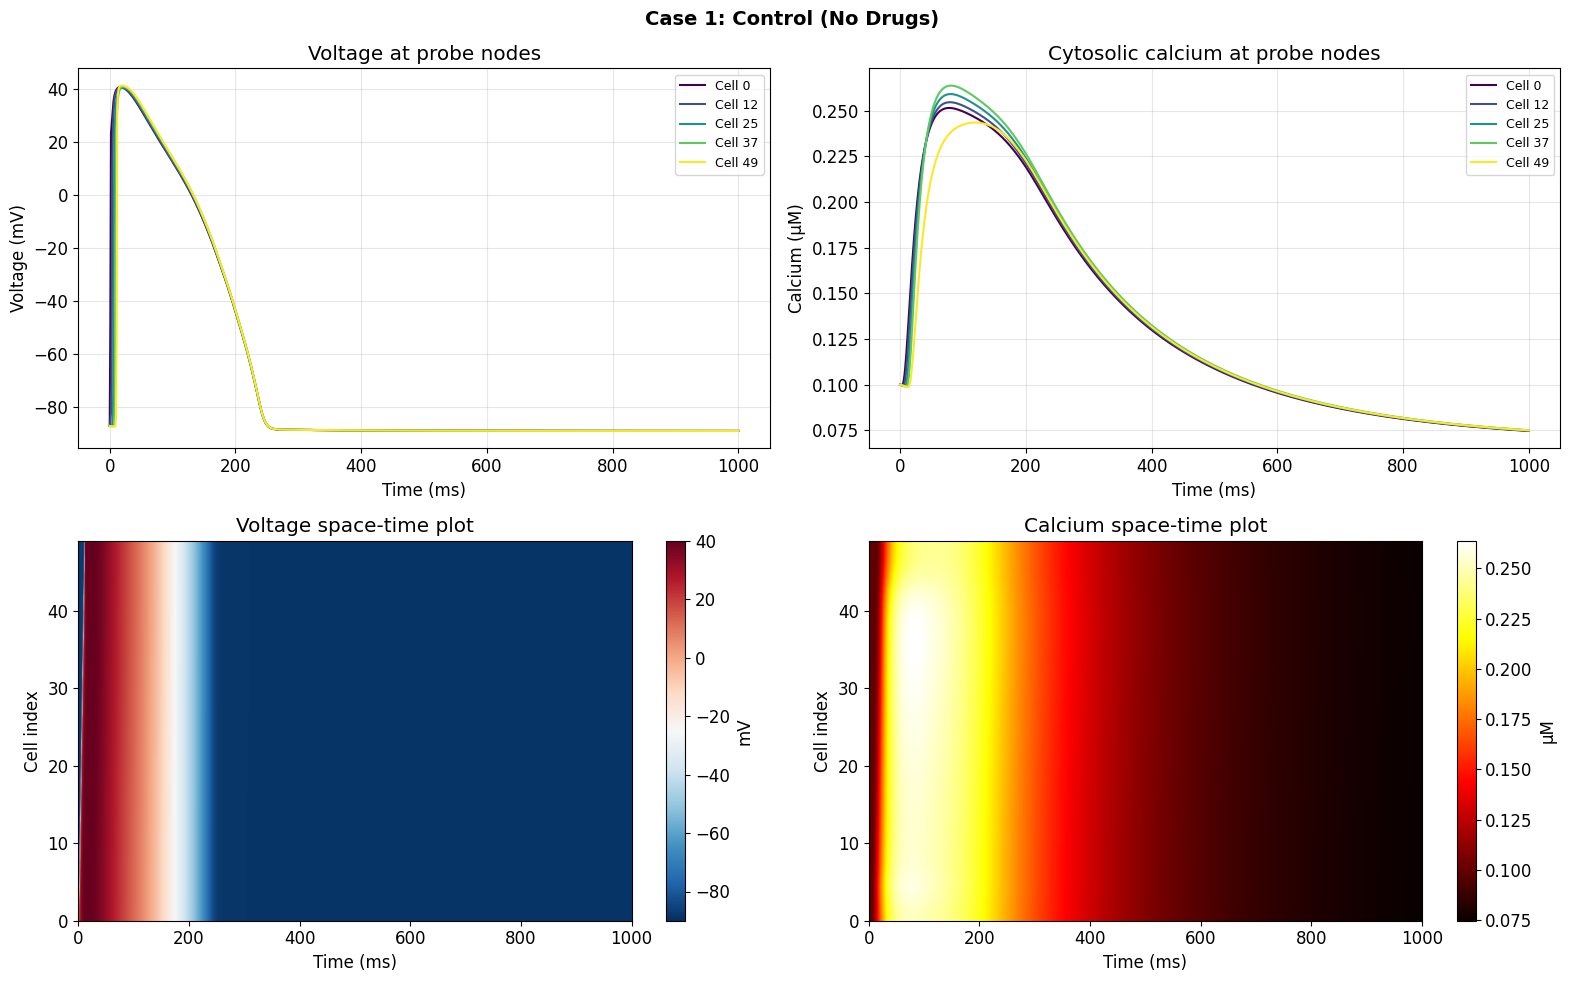

In [11]:
# Case 1: No drugs (Control)
print("\n--- CASE 1: Control (no drugs) ---")
result_control = run_cable_simulation(
    iso_uM=0.0, quinidine_nM=0.0,
    duration_ms=DURATION, cycle_length=CL, num_beats=NUM_BEATS,
    stim_nodes=STIM_NODES, regulation=True
)
plot_cable_results(result_control, 'Case 1: Control (No Drugs)');


--- CASE 2: Quinidine 3237 nM ---
=== Cable Simulation ===
  ISO: 0.0 µM, Quinidine: 3237.0 nM
  Duration: 1000.0 ms, 1 beat(s), CL=1000.0 ms
  Stim nodes: [0, 1, 2, 3, 4], amplitude: 80.0 µA/µF
  t = 0 / 1000 ms
  t = 100 / 1000 ms
  t = 200 / 1000 ms
  t = 300 / 1000 ms
  t = 400 / 1000 ms
  t = 500 / 1000 ms
  t = 600 / 1000 ms
  t = 700 / 1000 ms
  t = 800 / 1000 ms
  t = 900 / 1000 ms
  t = 1000 / 1000 ms
  ✓ COMPLETE | Quality: ✓ PASS | Runtime: 39.5s


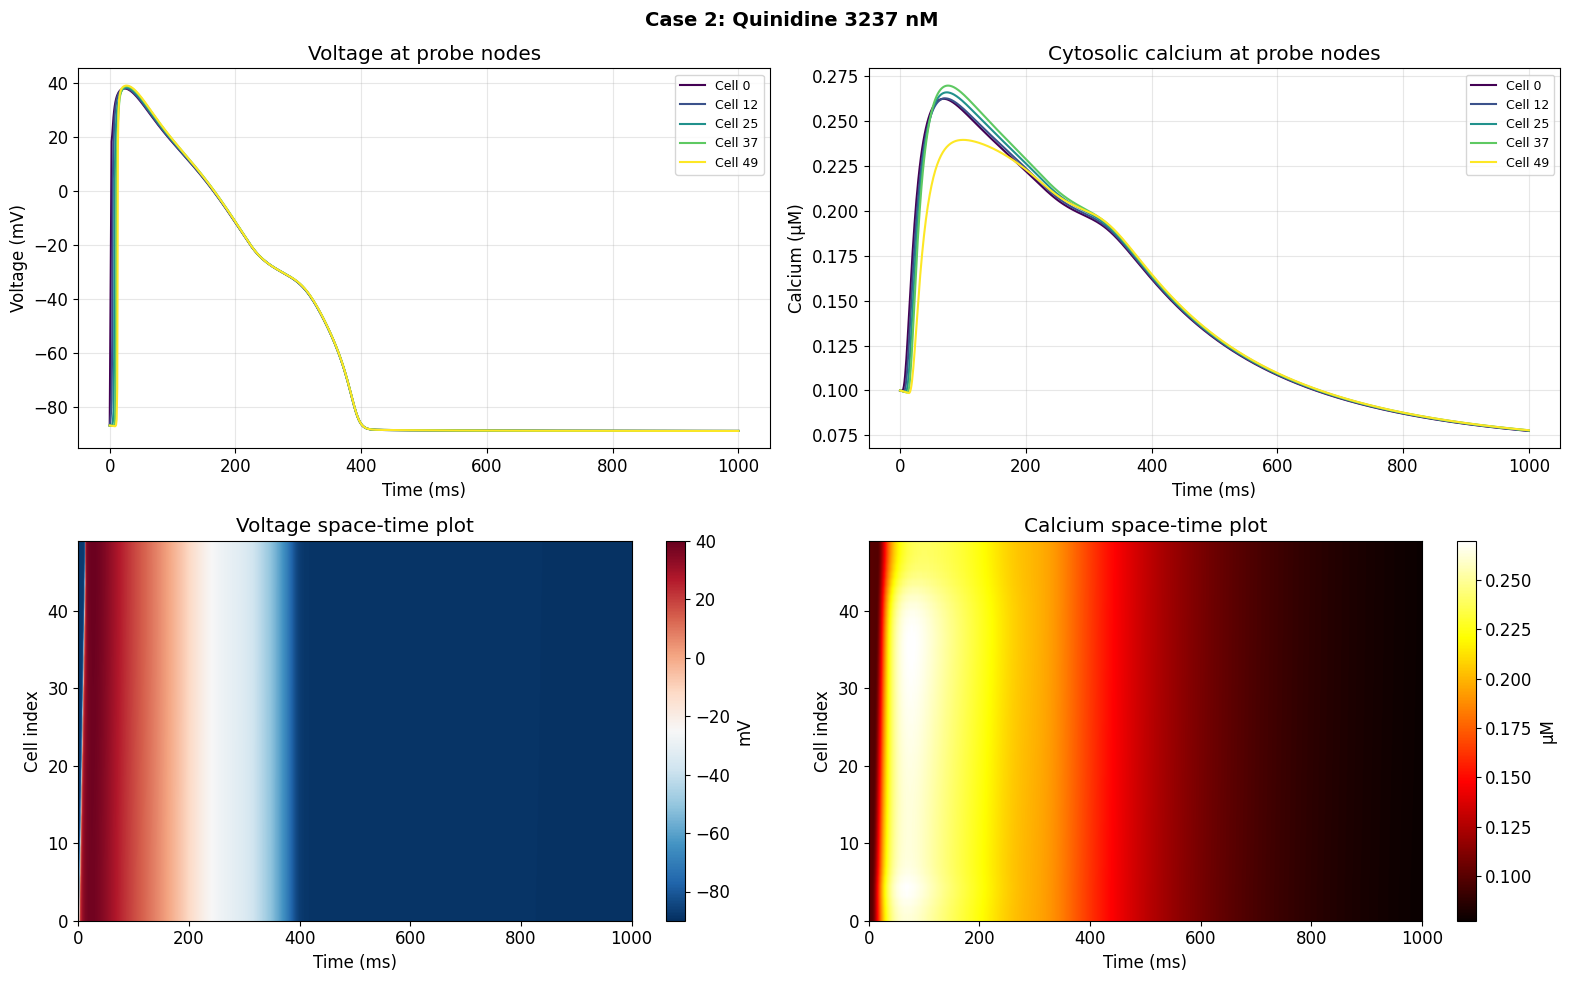

In [12]:
# Case 2: Quinidine alone (3237 nM)
print("\n--- CASE 2: Quinidine 3237 nM ---")
result_quin = run_cable_simulation(
    iso_uM=0.0, quinidine_nM=3237.0,
    duration_ms=DURATION, cycle_length=CL, num_beats=NUM_BEATS,
    stim_nodes=STIM_NODES, regulation=True
)
plot_cable_results(result_quin, 'Case 2: Quinidine 3237 nM');


--- CASE 3: ISO 1 µM ---
=== Cable Simulation ===
  ISO: 1.0 µM, Quinidine: 0.0 nM
  Duration: 1000.0 ms, 1 beat(s), CL=1000.0 ms
  Stim nodes: [0, 1, 2, 3, 4], amplitude: 80.0 µA/µF
  Pre-exposing signaling for 10000 s...
  Signaling pre-exposure complete.
  t = 0 / 1000 ms
  t = 100 / 1000 ms
  t = 200 / 1000 ms
  t = 300 / 1000 ms
  t = 400 / 1000 ms
  t = 500 / 1000 ms
  t = 600 / 1000 ms
  t = 700 / 1000 ms
  t = 800 / 1000 ms
  t = 900 / 1000 ms
  t = 1000 / 1000 ms
  ✓ COMPLETE | Quality: ✓ PASS | Runtime: 102.2s


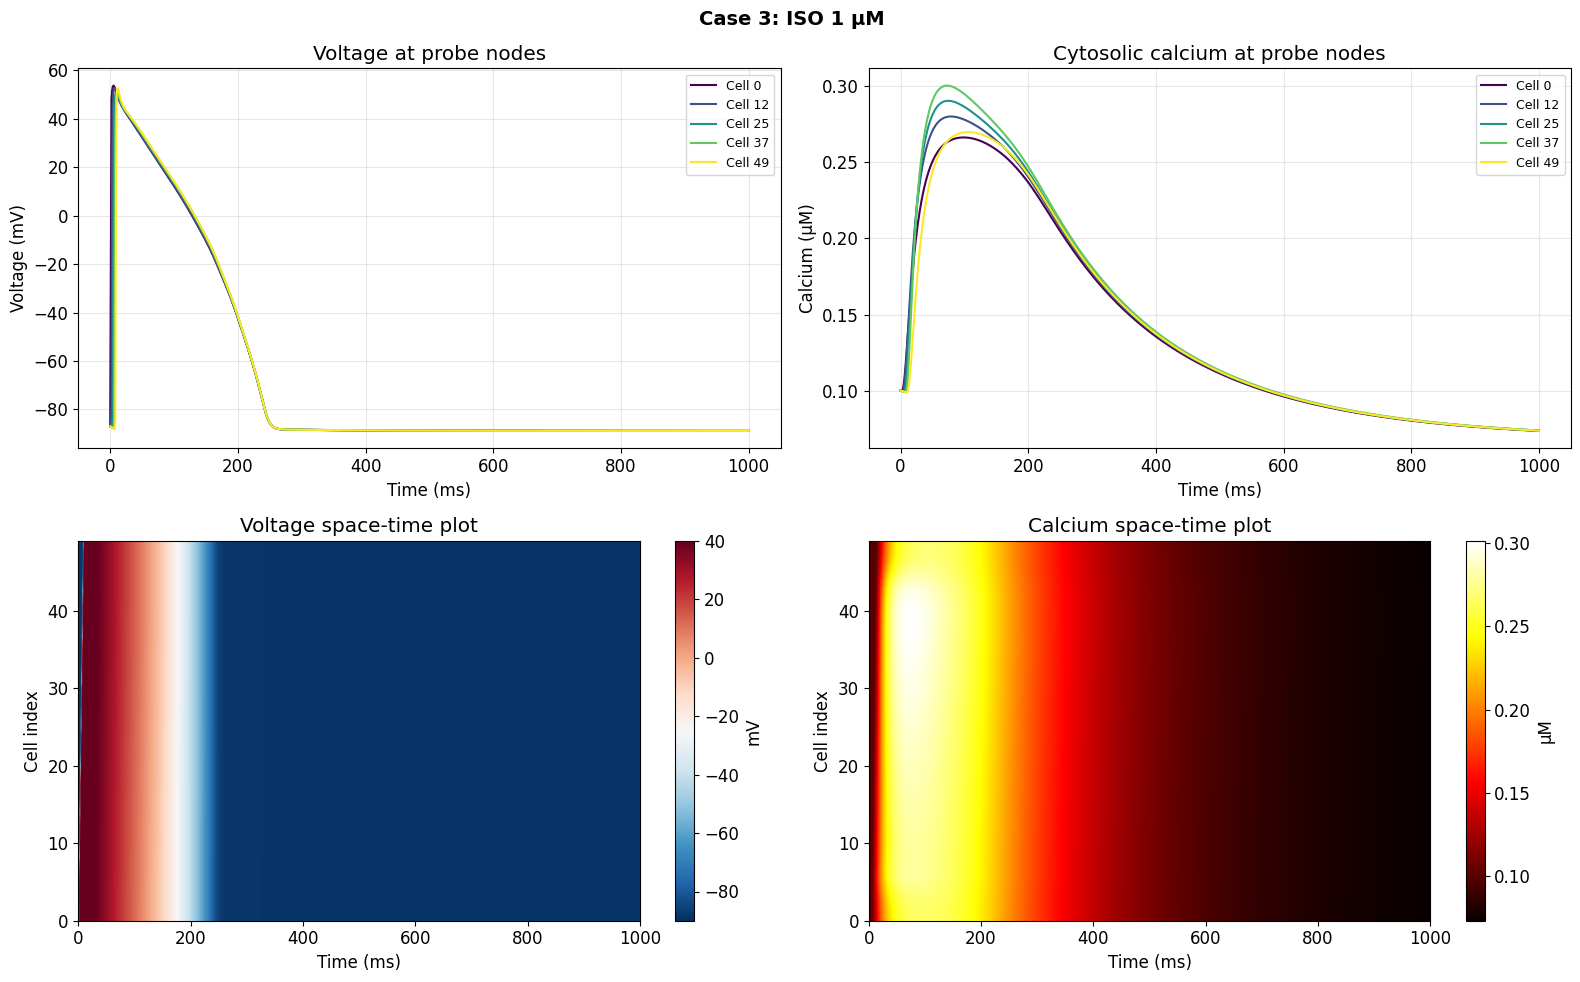

In [13]:
# Case 3: ISO alone (1 µM)
print("\n--- CASE 3: ISO 1 µM ---")
result_iso = run_cable_simulation(
    iso_uM=1.0, quinidine_nM=0.0,
    duration_ms=DURATION, cycle_length=CL, num_beats=NUM_BEATS,
    stim_nodes=STIM_NODES, regulation=True
)
plot_cable_results(result_iso, 'Case 3: ISO 1 µM');


--- CASE 4: ISO 1 µM + Quinidine 3237 nM ---
=== Cable Simulation ===
  ISO: 1.0 µM, Quinidine: 3237.0 nM
  Duration: 1000.0 ms, 1 beat(s), CL=1000.0 ms
  Stim nodes: [0, 1, 2, 3, 4], amplitude: 80.0 µA/µF
  Pre-exposing signaling for 10000 s...
  Signaling pre-exposure complete.
  t = 0 / 1000 ms
  t = 100 / 1000 ms
  t = 200 / 1000 ms
  t = 300 / 1000 ms
  t = 400 / 1000 ms
  t = 500 / 1000 ms
  t = 600 / 1000 ms
  t = 700 / 1000 ms
  t = 800 / 1000 ms
  t = 900 / 1000 ms
  t = 1000 / 1000 ms
  ✓ COMPLETE | Quality: ✓ PASS | Runtime: 83.4s


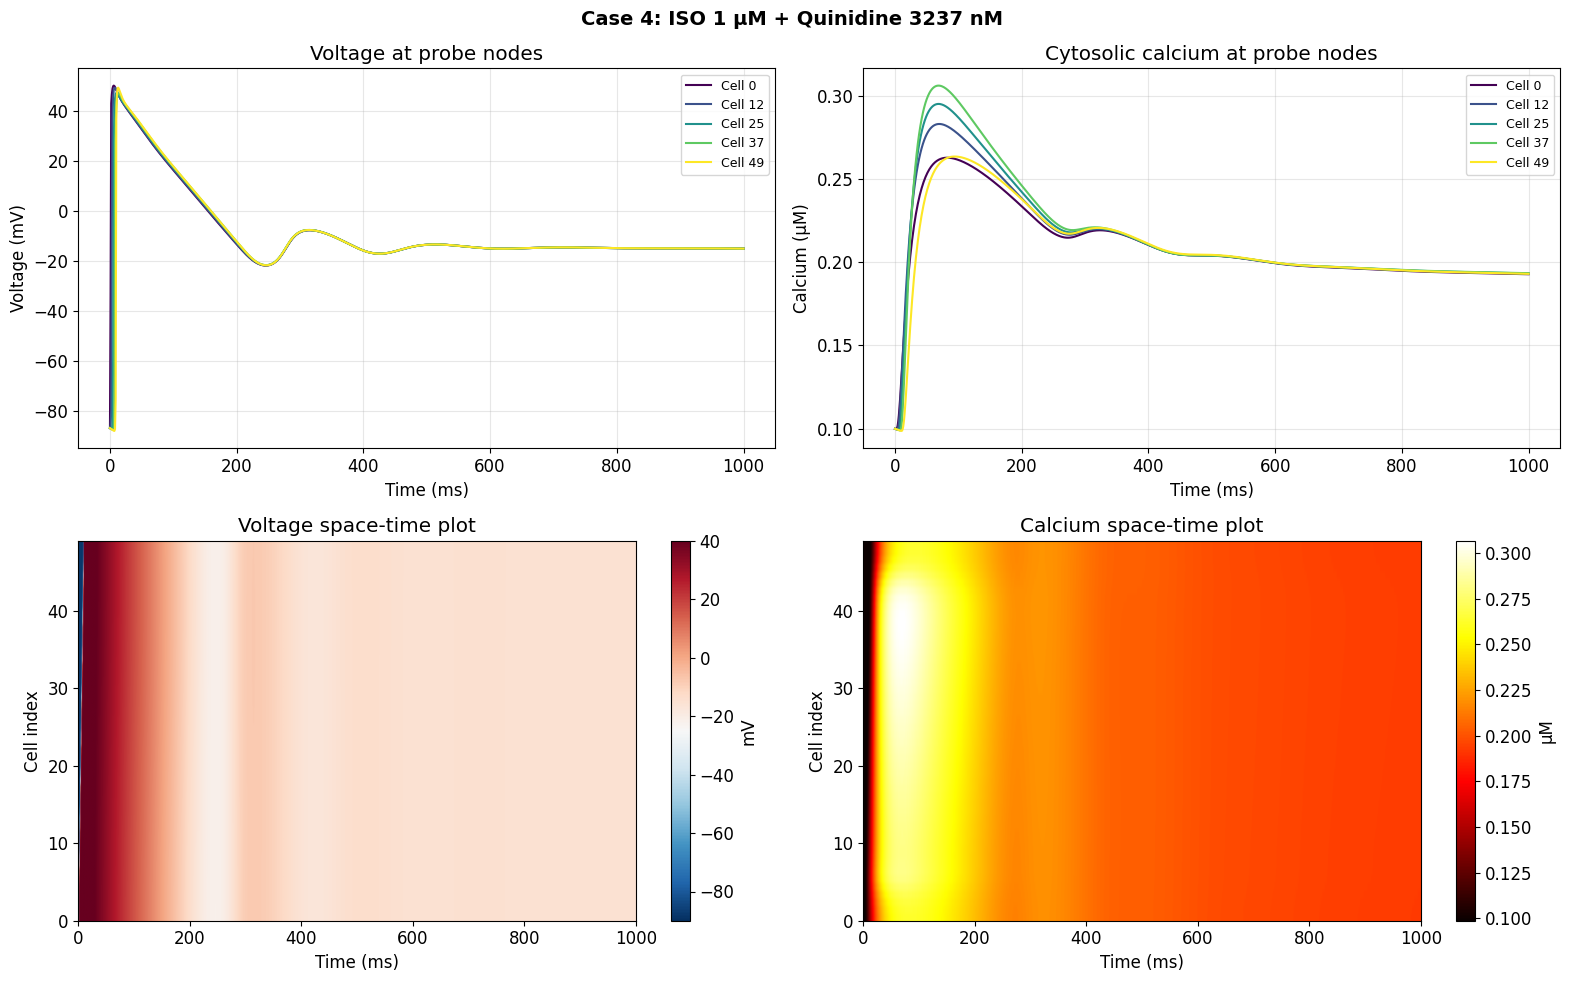

In [14]:
# Case 4: ISO + Quinidine
print("\n--- CASE 4: ISO 1 µM + Quinidine 3237 nM ---")
result_both = run_cable_simulation(
    iso_uM=1.0, quinidine_nM=3237.0,
    duration_ms=DURATION, cycle_length=CL, num_beats=NUM_BEATS,
    stim_nodes=STIM_NODES, regulation=True
)
plot_cable_results(result_both, 'Case 4: ISO 1 µM + Quinidine 3237 nM');

In [ ]:
# Comparison plot
results_all = [result_control, result_quin, result_iso, result_both]
labels_all = ['Control', 'Quinidine 3237 nM', 'ISO 1 µM', 'ISO + Quinidine']
plot_comparison(results_all, labels_all);

## 10. Test Suite

Numerical and physiological screening tests for each condition.

In [ ]:
def run_tests(result, label):
    """Run a battery of numerical and physiological screening tests."""
    tests = []
    t = result['timeMs']
    Vm = result['Vm']
    Cai = result['Cai']
    n = Vm.shape[1]

    # ---- Numerical quality tests ----
    # T1: All voltages are finite and real
    t1 = np.all(np.isfinite(Vm)) and np.all(np.isreal(Vm))
    tests.append(('Finite/real voltage', t1))

    # T2: All calcium concentrations are finite and non-negative
    t2 = np.all(np.isfinite(Cai)) and np.all(Cai >= 0)
    tests.append(('Non-negative calcium', t2))

    # T3: Ion boundary was not reached
    t3 = not result['quality']['ion_boundary']
    tests.append(('No ion boundary', t3))

    # T4: Simulation completed
    t4 = result['quality']['completed']
    tests.append(('Completed full duration', t4))

    # T5: Minimum ion concentration > 0
    t5 = result['quality']['min_ion'] > 0
    tests.append(('Positive ion concentrations', t5))

    # ---- Physiological screening tests ----
    # T6: Resting potential near -85 to -90 mV (at unstimulated distal cell)
    v_rest_distal = Vm[0, -1]
    t6 = -95.0 < v_rest_distal < -60.0
    tests.append((f'Resting potential ({v_rest_distal:.1f} mV)', t6))

    # T7: Action potential upstroke at stimulated cell
    v_max_cell0 = np.max(Vm[:, 0])
    t7 = v_max_cell0 > 0  # AP should overshoot 0 mV
    tests.append((f'AP upstroke at cell 0 (Vmax={v_max_cell0:.1f} mV)', t7))

    # T8: Propagation test — distal cell should activate
    v_max_distal = np.max(Vm[:, -1])
    t8 = v_max_distal > -30  # Should reach at least -30 mV if propagated
    tests.append((f'Propagation to distal cell (Vmax={v_max_distal:.1f} mV)', t8))

    # T9: Conduction velocity sanity check
    # Time from cell 0 to cell n-1 crossing -30 mV
    def find_activation(v_trace, threshold=-30):
        for i in range(len(v_trace)-1):
            if v_trace[i] < threshold and v_trace[i+1] >= threshold:
                return t[i] + (t[i+1] - t[i]) * (threshold - v_trace[i]) / (v_trace[i+1] - v_trace[i])
        return None

    t_act_0 = find_activation(Vm[:, 0])
    t_act_end = find_activation(Vm[:, -1])
    if t_act_0 is not None and t_act_end is not None:
        cv = (n - 1) * DX / ((t_act_end - t_act_0) / 1000.0)  # cm/s
        t9 = 10 < cv < 200  # Reasonable CV range for ventricular tissue
        tests.append((f'Conduction velocity ({cv:.1f} cm/s)', t9))
    else:
        tests.append(('Conduction velocity (no propagation)', False))

    # T10: APD90 at cell 0
    v0 = Vm[:, 0]
    if t_act_0 is not None:
        peak_idx = np.argmax(v0)
        v_peak = v0[peak_idx]
        v_rest = np.min(v0[:max(1, peak_idx)])
        apd_level = v_rest + 0.1 * (v_peak - v_rest)  # 90% repolarization
        # Find last crossing of APD level after peak
        apd90 = None
        for i in range(peak_idx, len(v0)-1):
            if v0[i] > apd_level and v0[i+1] <= apd_level:
                t_cross = t[i] + (t[i+1] - t[i]) * (apd_level - v0[i]) / (v0[i+1] - v0[i])
                apd90 = t_cross - t_act_0
        if apd90 is not None:
            t10 = 100 < apd90 < 600  # Reasonable APD range
            tests.append((f'APD90 at cell 0 ({apd90:.1f} ms)', t10))
        else:
            tests.append(('APD90 at cell 0 (not measurable)', False))
    else:
        tests.append(('APD90 at cell 0 (no activation)', False))

    # T11: Calcium transient
    ca_max_0 = np.max(Cai[:, 0]) * 1000  # µM
    t11 = ca_max_0 > 0.1  # Should have measurable calcium transient
    tests.append((f'Calcium transient ({ca_max_0:.3f} µM)', t11))

    # Print results
    print(f"\n{'='*60}")
    print(f"TEST RESULTS: {label}")
    print(f"{'='*60}")
    all_pass = True
    for name, passed in tests:
        status = '✓ PASS' if passed else '✗ FAIL'
        print(f"  {status}  {name}")
        if not passed:
            all_pass = False
    print(f"{'─'*60}")
    overall = '✓ ALL TESTS PASSED' if all_pass else '✗ SOME TESTS FAILED'
    print(f"  {overall}")
    print(f"  Runtime: {result['runtime_seconds']:.1f}s")

    return tests, all_pass

print("Test suite defined.")

In [ ]:
# Run tests for each condition
print("\n" + "#"*60)
print("# RUNNING TEST SUITE FOR ALL FOUR CONDITIONS")
print("#"*60)

test_labels = [
    'Case 1: No Drugs (Control)',
    'Case 2: Quinidine Alone (3237 nM)',
    'Case 3: ISO Alone (1 µM)',
    'Case 4: ISO + Quinidine'
]

all_tests = []
for result, label in zip(results_all, test_labels):
    tests, passed = run_tests(result, label)
    all_tests.append((label, tests, passed))

In [ ]:
# Summary table
print("\n" + "="*70)
print("SUMMARY")
print("="*70)
print(f"{'Condition':<40} {'Status':<15} {'Runtime (s)':<12}")
print("-"*70)
for i, (label, tests, passed) in enumerate(all_tests):
    status = '✓ PASS' if passed else '✗ FAIL'
    rt = results_all[i]['runtime_seconds']
    print(f"{label:<40} {status:<15} {rt:<12.1f}")
print("="*70)

## 11. Expected Behavior by Condition

### Case 1: No Drugs (Control)
- Normal action potential propagation along the cable
- Conduction velocity ~50-70 cm/s
- APD90 ~250-350 ms (endocardial)
- Normal calcium transient

### Case 2: Quinidine Alone (3237 nM)
- Reduced INa → slower conduction velocity
- Reduced IKr (hERG block) → prolonged APD
- Multi-channel block may partially compensate repolarization
- Possible conduction failure if INa block is severe

### Case 3: ISO Alone (1 µM)
- Enhanced ICaL (1.9×) → larger calcium transient, possible APD prolongation
- Enhanced IKs (8×) → counteracts ICaL prolongation
- Enhanced SERCA → faster calcium reuptake
- Net APD effect depends on ICaL/IKs balance
- **Known issue from MATLAB:** cajsr may reach zero → ionic boundary

### Case 4: ISO + Quinidine
- ISO + quinidine IKr block → enhanced repolarization delay
- ISO-enhanced ICaL + quinidine IKr block → potential for EAD
- Quinidine INa block + ISO → complex interaction
- **Known issue from MATLAB:** may stop at ionic boundary